In [ ]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from google.colab import drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:

file_path = '/content/drive/MyDrive/CBT dataset/Final_CBT_Dataset.csv'
df = pd.read_csv(file_path)
print('DataFrame loaded successfully.')

DataFrame loaded successfully.


In [ ]:
print(df.columns)
print(df.shape)

Index(['text', 'dominant_distortion', 'secondary_distortion'], dtype='object')
(2199, 3)


In [ ]:
df.head()

,text,dominant_distortion,secondary_distortion
0,"I feel hopeless, so my future is black, and no...",Emotional Reasoning,Overgeneralization
1,I'm stressed about how I'm going to pay off th...,No Distortion,NaN
2,"I love my new house, but the faucet leaks, so ...",Mental Filter,Overgeneralization
3,"I am a coward, and doing that brave thing once...",Labeling,Disqualifying the Positive
4,I'll never find a partner who understands me.,Jumping to Conclusions,NaN


In [ ]:
print(df['dominant_distortion'].value_counts())
print(df['secondary_distortion'].value_counts())

dominant_distortion
Emotional Reasoning              200
No Distortion                    200
Mental Filter                    200
Labeling                         200
Should Statements                200
Disqualifying the Positive       200
All-or-Nothing Thinking          200
Overgeneralization               200
Magnification or Minimization    200
Personalization                  200
Jumping to Conclusions           199
Name: count, dtype: int64
secondary_distortion
Labeling                         146
Jumping to Conclusions           106
All-or-Nothing Thinking          103
Overgeneralization                98
Magnification or Minimization     93
Should Statements                 92
Disqualifying the Positive        91
Emotional Reasoning               91
Mental Filter                     90
Personalization                   90
Name: count, dtype: int64


In [ ]:
print(df.isnull().sum())
print(df.shape)

text                       0
dominant_distortion        0
secondary_distortion    1199
dtype: int64
(2199, 3)


In [ ]:
# Fills empty cells with the string "None"
df.fillna({"secondary_distortion": "None"}, inplace=True)

In [ ]:
print(df.isnull().sum())
print(df.shape)

text                    0
dominant_distortion     0
secondary_distortion    0
dtype: int64
(2199, 3)


In [ ]:
# ============================================================
# DATA: load, build multi-hot labels (dominant+secondary),
# split into Train/Val/Test (stratified by dominant distortion)
# ============================================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Point to the NEW file we just created
DATA_PATH = '/content/Final_CBT_Dataset.csv'
df = pd.read_csv(DATA_PATH)

# 2. Use the clean column names we just created
col_text = "text"
col_dom  = "dominant_distortion"
col_sec  = "secondary_distortion"

# 3. Clean up the text data
df[col_text] = df[col_text].fillna("").astype(str)
df[col_dom]  = df[col_dom].fillna("").astype(str).str.strip()
df[col_sec]  = df[col_sec].fillna("").astype(str).str.strip()

# 4. Define "No Distortion" Handling
NO_DISTORTION = "no distortion"
def is_no_distortion(x: str) -> bool:
    # Check against our dataset's specific label
    return x.strip().lower() in [NO_DISTORTION, "none", "nan"]

# 5. Build Label Set (Excluding "No Distortion")
# This creates a list of just the 10 distortions
label_names = sorted(set(
    [x for x in df[col_dom].unique() if x and not is_no_distortion(x)] +
    [x for x in df[col_sec].unique() if x and not is_no_distortion(x)]
))

label2id = {l:i for i,l in enumerate(label_names)}
id2label = {i:l for l,i in label2id.items()}
num_labels = len(label_names)

print(f"num_labels: {num_labels}")
print(f"label_names: {label_names}")

# 6. Create Multi-Hot Vectors (The All-Zero Logic)
def to_multihot(row):
    y = np.zeros(num_labels, dtype=np.float32)
    dom = row[col_dom]
    sec = row[col_sec]

    # Add dominant if valid
    if dom and (not is_no_distortion(dom)) and dom in label2id:
        y[label2id[dom]] = 1.0

    # Add secondary if valid and different
    if sec and (not is_no_distortion(sec)) and sec in label2id and sec != dom:
        y[label2id[sec]] = 1.0
    return y

df["labels"] = df.apply(to_multihot, axis=1)

# Check our work
Y_all = np.stack(df["labels"].to_numpy())
print("Total examples:", len(df))
print("Examples with Distortion:", int((Y_all.sum(axis=1) > 0).sum()))
print("Examples Clean (No Distortion):", int((Y_all.sum(axis=1) == 0).sum()))

# 7. Stratified Split (70/15/15)
# We stratify by Dominant Distortion to ensure balance
SEED = 42
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df[col_dom]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df[col_dom]
)

print("-" * 30)
print(f"Train Size: {len(train_df)}")
print(f"Val Size:   {len(val_df)}")
print(f"Test Size:  {len(test_df)}")
print("-" * 30)

num_labels: 10
label_names: ['All-or-Nothing Thinking', 'Disqualifying the Positive', 'Emotional Reasoning', 'Jumping to Conclusions', 'Labeling', 'Magnification or Minimization', 'Mental Filter', 'Overgeneralization', 'Personalization', 'Should Statements']
Total examples: 2199
Examples with Distortion: 1999
Examples Clean (No Distortion): 200
------------------------------
Train Size: 1539
Val Size:   330
Test Size:  330
------------------------------


In [ ]:
# ============================================================
# STAGE 1 (FIXED): RoBERTa-large multi-label (dominant+secondary)
# Data columns: text, dominant_distortion, secondary_distortion
# - Dominant includes "No Distortion" => ALL-ZERO label vector
# - Secondary missing => "None" => ignored
# - Train/Val/Test = 70/15/15 stratified by dominant key
# - pos_weight = sqrt(neg/pos) from TRAIN only
# - best checkpoint by eval_loss
# - tune per-label thresholds on VAL only (0.01 grid)
# - final report on TEST
# - save model + tokenizer + thresholds json
# ============================================================

import os, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# ----------------------------
# 0) CONFIG
# ----------------------------
SEED = 42
DATA_PATH = "/content/drive/MyDrive/CBT dataset/Final_CBT_Dataset.csv"
MODEL_NAME = "roberta-large"

MAX_LEN = 512
OUT_DIR = "/content/roberta_stage1_fixed"
FINAL_DIR = "/content/roberta_stage1_fixed_final"

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FINAL_DIR, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)

# ----------------------------
# 1) LOAD + CLEAN
# ----------------------------
df = pd.read_csv(DATA_PATH)

col_text = "text"
col_dom  = "dominant_distortion"
col_sec  = "secondary_distortion"

df[col_text] = df[col_text].fillna("").astype(str)
df[col_dom]  = df[col_dom].fillna("No Distortion").astype(str).str.strip()
df[col_sec]  = df[col_sec].fillna("None").astype(str).str.strip()

# normalize whitespace
df[col_dom] = df[col_dom].str.replace(r"\s+", " ", regex=True)
df[col_sec] = df[col_sec].str.replace(r"\s+", " ", regex=True)

# ----------------------------
# 2) DEFINE LABELS (fixed 10 types)
# ----------------------------
target_labels = [
    "All-or-Nothing Thinking",
    "Disqualifying the Positive",
    "Emotional Reasoning",
    "Jumping to Conclusions",
    "Labeling",
    "Magnification or Minimization",
    "Mental Filter",
    "Overgeneralization",
    "Personalization",
    "Should Statements",
]
label2id = {l:i for i,l in enumerate(target_labels)}
id2label = {i:l for l,i in label2id.items()}
num_labels = len(target_labels)

NO_STRINGS = {"no distortion", "none", "nan", ""}

def clean_label(x):
    if pd.isna(x):
        return None
    s = str(x).strip()
    if s.lower() in NO_STRINGS:
        return None
    # Only keep labels that are in the 10-class set
    return s if s in label2id else None

def to_multihot(row):
    y = np.zeros(num_labels, dtype=np.float32)
    dom = clean_label(row[col_dom])
    sec = clean_label(row[col_sec])

    if dom is not None:
        y[label2id[dom]] = 1.0
    if sec is not None and sec != dom:
        y[label2id[sec]] = 1.0
    return y

df["labels"] = df.apply(to_multihot, axis=1)

Y_all = np.stack(df["labels"].to_numpy())
print("Total examples:", len(df))
print("Examples with ≥1 distortion:", int((Y_all.sum(axis=1) > 0).sum()))
print("Examples clean (No Distortion):", int((Y_all.sum(axis=1) == 0).sum()))

# stratify key: dominant distortion, but map "No Distortion" to itself
def dom_key(x):
    s = str(x).strip()
    return s if s in label2id else "No Distortion"

df["_dom_key"] = df[col_dom].apply(dom_key)

# ----------------------------
# 3) SPLIT: 70/15/15 (stratified by dominant)
# ----------------------------
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df["_dom_key"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["_dom_key"]
)

print("-"*45)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("-"*45)

# ----------------------------
# 4) TOKENIZATION (dynamic padding)
# ----------------------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def make_ds(df_):
    ds = Dataset.from_pandas(df_[[col_text, "labels"]].rename(columns={col_text: "text"}))
    def tok(batch):
        return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)
    ds = ds.map(tok, batched=True, remove_columns=["text"])
    ds.set_format("torch")
    return ds

train_ds = make_ds(train_df)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

# ----------------------------
# 5) POS_WEIGHT (sqrt(neg/pos) from TRAIN only)
# ----------------------------
Y_train = np.stack(train_df["labels"].to_numpy()).astype(np.float32)
pos = Y_train.sum(axis=0)
neg = Y_train.shape[0] - pos
pos_weight = torch.tensor(np.sqrt((neg + 1.0) / (pos + 1.0)), dtype=torch.float32)

print("pos counts (train):", pos.astype(int))
print("pos_weight:", pos_weight)

# ----------------------------
# 6) MODEL
# ----------------------------
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    problem_type="multi_label_classification"
)

# ----------------------------
# 7) TRAINER (weighted BCE)
# ----------------------------
class WeightedTrainer(Trainer):
    def __init__(self, pos_weight, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight = pos_weight

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.pop("labels").float()
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight.to(logits.device))
        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss

LOG_THRESH = 0.5
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1/(1+np.exp(-logits))
    preds = (probs >= LOG_THRESH).astype(int)
    return {
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "micro_precision": precision_score(labels, preds, average="micro", zero_division=0),
        "micro_recall": recall_score(labels, preds, average="micro", zero_division=0),
    }

args = TrainingArguments(
    output_dir=OUT_DIR,
    learning_rate=1e-5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=8,  # effective batch 16
    num_train_epochs=7,
    fp16=True,
    gradient_checkpointing=True,


    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,

    # FIX: choose best checkpoint by eval_loss (validation loss)
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    report_to="none",
    logging_steps=50,
    seed=SEED
)

trainer = WeightedTrainer(
    pos_weight=pos_weight,
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("\n Training Stage 1 (RoBERTa-large, fixed)...")
trainer.train()

# ----------------------------
# 8) THRESHOLD TUNING ON VAL ONLY (0.01 grid)
# ----------------------------
print("\n Tuning thresholds on VAL...")
val_out = trainer.predict(val_ds)
val_probs = 1/(1+np.exp(-val_out.predictions))
Y_val = np.stack(val_df["labels"].to_numpy()).astype(int)

thr = np.zeros(num_labels, dtype=np.float32)
grid = np.linspace(0.01, 0.99, 99)

for j in range(num_labels):
    best_t, best_f1 = 0.5, -1.0
    for t in grid:
        pj = (val_probs[:, j] >= t).astype(int)
        f1j = f1_score(Y_val[:, j], pj, zero_division=0)
        if f1j > best_f1:
            best_f1, best_t = float(f1j), float(t)
    thr[j] = best_t

thr_dict = {target_labels[i]: float(thr[i]) for i in range(num_labels)}
print("VAL thresholds:", thr_dict)

# ----------------------------
# 9) FINAL EVAL ON TEST (tuned thresholds)
# ----------------------------
print("\n Final evaluation on TEST...")
test_out = trainer.predict(test_ds)
test_probs = 1/(1+np.exp(-test_out.predictions))
Y_test = np.stack(test_df["labels"].to_numpy()).astype(int)

test_hat = (test_probs >= thr).astype(int)

print("\n" + "="*60)
print("FINAL STAGE 1 REPORT (TEST; thresholds tuned on VAL)")
print("="*60)
print(classification_report(Y_test, test_hat, target_names=target_labels, digits=4, zero_division=0))

final_metrics = {
    "macro_f1": float(f1_score(Y_test, test_hat, average="macro", zero_division=0)),
    "micro_f1": float(f1_score(Y_test, test_hat, average="micro", zero_division=0)),
    "micro_precision": float(precision_score(Y_test, test_hat, average="micro", zero_division=0)),
    "micro_recall": float(recall_score(Y_test, test_hat, average="micro", zero_division=0)),
    "pred_pos": int(test_hat.sum()),
    "true_pos": int(Y_test.sum()),
}
print(final_metrics)

# ----------------------------
# 10) SAVE MODEL + TOKENIZER + THRESHOLDS
# ----------------------------
print("\n Saving final model + thresholds...")
trainer.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)

with open(os.path.join(FINAL_DIR, "thresholds_val.json"), "w") as f:
    json.dump({"thresholds": thr_dict, "labels": target_labels}, f, indent=2)

with open(os.path.join(FINAL_DIR, "stage1_test_metrics.json"), "w") as f:
    json.dump(final_metrics, f, indent=2)

print("Saved to:", FINAL_DIR)


Total examples: 2199
Examples with ≥1 distortion: 1999
Examples clean (No Distortion): 200
---------------------------------------------
Train: 1539 | Val: 330 | Test: 330
---------------------------------------------


Map:   0%|          | 0/1539 [00:00<?, ? examples/s]

Map:   0%|          | 0/330 [00:00<?, ? examples/s]

Map:   0%|          | 0/330 [00:00<?, ? examples/s]

pos counts (train): [210 211 207 206 240 208 199 209 204 209]
pos_weight: tensor([2.5106, 2.5038, 2.5315, 2.5386, 2.3225, 2.5245, 2.5894, 2.5176, 2.5529,
        2.5176])


...


 Tuning thresholds on VAL...


VAL thresholds: {'All-or-Nothing Thinking': 0.33000001311302185, 'Disqualifying the Positive': 0.2800000011920929, 'Emotional Reasoning': 0.33000001311302185, 'Jumping to Conclusions': 0.3499999940395355, 'Labeling': 0.3799999952316284, 'Magnification or Minimization': 0.41999998688697815, 'Mental Filter': 0.33000001311302185, 'Overgeneralization': 0.5699999928474426, 'Personalization': 0.25, 'Should Statements': 0.3199999928474426}

 Final evaluation on TEST...



FINAL STAGE 1 REPORT (TEST; thresholds tuned on VAL)
                               precision    recall  f1-score   support

      All-or-Nothing Thinking     0.7368    0.8400    0.7850        50
   Disqualifying the Positive     0.9149    1.0000    0.9556        43
          Emotional Reasoning     0.9730    1.0000    0.9863        36
       Jumping to Conclusions     0.8600    0.9149    0.8866        47
                     Labeling     0.8393    0.9592    0.8952        49
Magnification or Minimization     0.8718    0.8500    0.8608        40
                Mental Filter     0.8958    0.9556    0.9247        45
           Overgeneralization     0.9778    0.9362    0.9565        47
              Personalization     0.8936    0.9333    0.9130        45
            Should Statements     0.8936    1.0000    0.9438        42

                    micro avg     0.8795    0.9369    0.9073       444
                    macro avg     0.8857    0.9389    0.9108       444
                 weig

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: /content/roberta_stage1_fixed_final


In [ ]:
from google.colab import drive
import shutil
import os

# 1. Mount Drive
#drive.mount('/content/drive')

MODEL_DIR = "/content/roberta_stage1_fixed_final"
ZIP_PATH = "/content/roberta_stage1_fixed_final.zip"

# 2. Zip the model
shutil.make_archive(
    base_name="/content/roberta_stage1_fixed_final",
    format="zip",
    root_dir=MODEL_DIR
)

# 3. Copy zip to Drive
DEST_PATH = "/content/drive/MyDrive/CBT_Models/roberta_stage1_fixed_final.zip"

os.makedirs("/content/drive/MyDrive/CBT_Models", exist_ok=True)
shutil.copy(ZIP_PATH, DEST_PATH)

print(" Model zipped and uploaded to Drive:")
print(DEST_PATH)


In [ ]:
from google.colab import drive
import zipfile
import os

# 1. Mount Drive
drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/CBT_Models/roberta_stage1_fixed_final.zip"
EXTRACT_PATH = "/content/roberta_stage1_fixed_final"

# 2. Extract
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("✅ Model extracted to:", EXTRACT_PATH)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Model extracted to: /content/roberta_stage1_fixed_final


In [ ]:
from google.colab import drive
import zipfile
import os

# 1. Mount Drive
drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/CBT_Models/roberta_stage1_fixed_final.zip"
EXTRACT_PATH = "/content/roberta_stage1_fixed_final"

# 2. Extract
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("✅ Model extracted to:", EXTRACT_PATH)


Mounted at /content/drive
✅ Model extracted to: /content/roberta_stage1_fixed_final


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_PATH = "/content/roberta_stage1_fixed_final"

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

In [ ]:
import json

with open(os.path.join(MODEL_PATH, "thresholds_val.json")) as f:
    BEST_THRESHOLDS = json.load(f)

print("Loaded thresholds:", BEST_THRESHOLDS)


Loaded thresholds: {'thresholds': {'All-or-Nothing Thinking': 0.33000001311302185, 'Disqualifying the Positive': 0.2800000011920929, 'Emotional Reasoning': 0.33000001311302185, 'Jumping to Conclusions': 0.3499999940395355, 'Labeling': 0.3799999952316284, 'Magnification or Minimization': 0.41999998688697815, 'Mental Filter': 0.33000001311302185, 'Overgeneralization': 0.5699999928474426, 'Personalization': 0.25, 'Should Statements': 0.3199999928474426}, 'labels': ['All-or-Nothing Thinking', 'Disqualifying the Positive', 'Emotional Reasoning', 'Jumping to Conclusions', 'Labeling', 'Magnification or Minimization', 'Mental Filter', 'Overgeneralization', 'Personalization', 'Should Statements']}


In [ ]:
#=========================================================
# ONE CELL: SINGLE MULTITASK MODEL (ROBERTA-LARGE from YOUR STAGE1 PATH)
# - Uses DYNAMIC PADDING (DataCollatorWithPadding) ✅
# - Preserves multitask labels via custom collator ✅
# - Real-only split train/val/test (stratified) ✅
# - Smart Text v2: distorted_part [SEP] full_text ✅
# - 3 heads in ONE model:
#     (A) 10-label multilabel distortion head (canonical 10)
#     (B) binary has_distortion head (No Distortion vs Has Distortion)
#     (C) JTC subtype head (Fortune-telling vs Mind Reading; -100 ignored)
# - pos_weight (clamped) + weighted binary CE ✅
# - Early stopping ✅
# - Threshold tuning on VAL ✅
# - Top-2 constrained decode ✅
# - JTC subtype eval (masked: subtype labeled & predicted JTC & passed gate) ✅
# Saves ONE MODEL folder with thresholds + meta.
# Works with transformers==5.0.0 (uses eval_strategy + label_names) ✅
# =========================================================

import os, json, random, inspect
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report

import transformers
from transformers import (
    AutoTokenizer,
    AutoConfig,
    AutoModel,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    set_seed,
    DataCollatorWithPadding
)

print("transformers version:", transformers.__version__)

# -----------------------
# CONFIG
# -----------------------
SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

STAGE1_MODEL_PATH = "/content/roberta_stage1_fixed_final"  # your roberta-large stage1 checkpoint
REAL_PATH         = "/content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv"
OUT_DIR           = "/content/roberta_large_multitask_single_model_final_dynpad"
os.makedirs(OUT_DIR, exist_ok=True)

MAX_LEN = 512
LR = 8e-6
WEIGHT_DECAY = 0.05
EPOCHS = 6
PATIENCE = 2

PER_DEVICE_TRAIN_BS = 1
GRAD_ACCUM = 16
PER_DEVICE_EVAL_BS = 4

# loss weights
LAMBDA_10  = 1.0
LAMBDA_BIN = 1.0
LAMBDA_JTC = 1.0

# decoding knobs
DOM_FLOOR = 0.25
SEC_FLOOR = 0.20
SEC_RATIO = 0.75

# -----------------------
# LABELS (10 canonical; No Distortion handled by binary head)
# -----------------------
target_labels = [
    "All-or-Nothing Thinking",
    "Disqualifying the Positive",
    "Emotional Reasoning",
    "Jumping to Conclusions",
    "Labeling",
    "Magnification or Minimization",
    "Mental Filter",
    "Overgeneralization",
    "Personalization",
    "Should Statements",
]
label2id = {l:i for i,l in enumerate(target_labels)}
id2label = {i:l for l,i in label2id.items()}
num_labels = len(target_labels)

label_map = {
    "mind reading": "Jumping to Conclusions",
    "fortune-telling": "Jumping to Conclusions",
    "jumping to conclusions": "Jumping to Conclusions",
    "magnification": "Magnification or Minimization",
    "minimization": "Magnification or Minimization",
    "magnification or minimization": "Magnification or Minimization",
    "all-or-nothing thinking": "All-or-Nothing Thinking",
    "overgeneralization": "Overgeneralization",
    "mental filter": "Mental Filter",
    "disqualifying the positive": "Disqualifying the Positive",
    "emotional reasoning": "Emotional Reasoning",
    "should statements": "Should Statements",
    "labeling": "Labeling",
    "personalization": "Personalization",
    "no distortion": "No Distortion",
    "none": "No Distortion",
    "nan": "No Distortion",
    "": "No Distortion",
}

def clean_label(x):
    if pd.isna(x):
        return "No Distortion"
    s = str(x).strip().lower()
    if s in label_map:
        return label_map[s]
    for t in target_labels:
        if s == t.lower():
            return t
    return "No Distortion"

def to_multihot(dom_raw, sec_raw):
    y = np.zeros(num_labels, dtype=np.float32)
    dom = clean_label(dom_raw)
    sec = clean_label(sec_raw)
    if dom in label2id:
        y[label2id[dom]] = 1.0
    if sec in label2id and sec != dom:
        y[label2id[sec]] = 1.0
    return y

def has_distortion(dom_raw):
    return 0 if clean_label(dom_raw) == "No Distortion" else 1

def norm_raw(x):
    return str(x).strip().lower()

def extract_subtype(dom_raw, sec_raw):
    d, s = norm_raw(dom_raw), norm_raw(sec_raw)
    if d in ["mind reading", "fortune-telling"]:
        return d
    if s in ["mind reading", "fortune-telling"]:
        return s
    return None

# -----------------------
# LOAD REAL + BUILD INPUTS
# -----------------------
df = pd.read_csv(REAL_PATH)

def find_col(df_, keys):
    for c in df_.columns:
        cl = c.lower().strip()
        for k in keys:
            if k.lower() in cl:
                return c
    raise KeyError(f"Could not find column matching {keys}. Available columns: {list(df_.columns)}")

c_full = find_col(df, ["patient question", "question"])
c_span = find_col(df, ["distorted part", "distorted_part"])
c_dom  = find_col(df, ["dominant"])
c_sec  = find_col(df, ["secondary"])

df = df[[c_full, c_span, c_dom, c_sec]].copy()
df.columns = ["full_text", "dist_part", "dom_raw", "sec_raw"]
df["full_text"] = df["full_text"].fillna("").astype(str)
df["dist_part"] = df["dist_part"].fillna("").astype(str)
df["dom_canon"] = df["dom_raw"].apply(clean_label)

def build_input_text(row):
    dom = clean_label(row["dom_raw"])
    full_text = row["full_text"]
    span = row["dist_part"].strip()
    if dom == "No Distortion":
        return full_text
    if span and span.lower() != "nan":
        return f"{span} [SEP] {full_text}"
    return full_text

df["text"] = df.apply(build_input_text, axis=1)

df["y10"]  = [to_multihot(d, s) for d, s in zip(df["dom_raw"], df["sec_raw"])]
df["ybin"] = df["dom_raw"].apply(has_distortion).astype(int)

# subtype: 1=MR, 0=FT, -100 ignore
yjtc = []
for d,s in zip(df["dom_raw"], df["sec_raw"]):
    st = extract_subtype(d,s)
    if st is None:
        yjtc.append(-100)
    else:
        yjtc.append(1 if st == "mind reading" else 0)
df["yjtc"] = np.array(yjtc, dtype=np.int64)

print("Total real samples:", len(df))
print("JTC subtype labeled rows:", int((df["yjtc"] != -100).sum()))

# -----------------------
# SPLIT REAL
# -----------------------
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df["dom_canon"])
val_df, test_df   = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["dom_canon"])
print(f"\nSplit => train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")

# -----------------------
# TOKENIZER + DATASETS (DYNAMIC PADDING)
# -----------------------
tokenizer = AutoTokenizer.from_pretrained(STAGE1_MODEL_PATH, use_fast=True)

def make_ds(df_):
    ds = Dataset.from_pandas(df_[["text", "y10", "ybin", "yjtc"]])

    def tok(batch):
        enc = tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LEN
        )
        enc["labels"] = batch["y10"]          # list[list[float]] length=10
        enc["labels_bin"] = batch["ybin"]     # list[int]
        enc["labels_jtc"] = batch["yjtc"]     # list[int]
        return enc

    ds = ds.map(tok, batched=True, remove_columns=["text"])
    return ds

train_ds = make_ds(train_df)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

# -----------------------
# CUSTOM COLLATOR (DYNAMIC PAD + KEEP LABELS)
# -----------------------
base_collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")

class MultiTaskDataCollator:
    def __call__(self, features):
        labels     = [f.pop("labels", f.pop("y10")) for f in features]
        labels_bin = [f.pop("labels_bin", f.pop("ybin")) for f in features]
        labels_jtc = [f.pop("labels_jtc", f.pop("yjtc")) for f in features]

        for f in features:
            f.pop("__index_level_0__", None)

        batch = base_collator(features)
        batch["labels"] = torch.tensor(labels, dtype=torch.float32)
        batch["labels_bin"] = torch.tensor(labels_bin, dtype=torch.long)
        batch["labels_jtc"] = torch.tensor(labels_jtc, dtype=torch.long)
        return batch

data_collator = MultiTaskDataCollator()
_tmp = data_collator([train_ds[i] for i in range(2)])
print("Collator keys:", _tmp.keys(), "| input_ids:", _tmp["input_ids"].shape, "| labels:", _tmp["labels"].shape)

# -----------------------
# POS WEIGHTS (10-head)
# -----------------------
Y_train = np.stack(train_df["y10"].to_numpy()).astype(np.float32)
pos = Y_train.sum(axis=0)
neg = Y_train.shape[0] - pos
pos_weight = (neg / (pos + 1e-6)).astype(np.float32)
pos_weight = np.clip(pos_weight, 1.0, 30.0)
pos_weight_t = torch.tensor(pos_weight, dtype=torch.float32)
print("\npos_weight (clamped):", {target_labels[i]: float(pos_weight[i]) for i in range(num_labels)})

# binary pos weight for CE
ybin_train = train_df["ybin"].to_numpy()
posb = ybin_train.sum()
negb = len(ybin_train) - posb
w_pos_bin = float(negb / (posb + 1e-6))
w_pos_bin = min(max(w_pos_bin, 1.0), 30.0)
print("Binary pos_weight:", w_pos_bin)

# -----------------------
# SINGLE MULTITASK MODEL (ONE MODEL)
# -----------------------
class RobertaMultiTask(nn.Module):
    def __init__(self, base_path, num_labels_10=10):
        super().__init__()
        self.config = AutoConfig.from_pretrained(base_path)
        self.encoder = AutoModel.from_pretrained(base_path, config=self.config)

        hidden = self.config.hidden_size
        dropout = getattr(self.config, "hidden_dropout_prob", 0.1)
        self.drop = nn.Dropout(dropout)

        self.head_10  = nn.Linear(hidden, num_labels_10)
        self.head_bin = nn.Linear(hidden, 2)
        self.head_jtc = nn.Linear(hidden, 2)

        if hasattr(self.encoder, "gradient_checkpointing_enable"):
            self.encoder.gradient_checkpointing_enable()

    def gradient_checkpointing_enable(self, gradient_checkpointing_kwargs=None):
        if hasattr(self.encoder, "gradient_checkpointing_enable"):
            self.encoder.gradient_checkpointing_enable()

    def gradient_checkpointing_disable(self):
        if hasattr(self.encoder, "gradient_checkpointing_disable"):
            self.encoder.gradient_checkpointing_disable()

    # ✅ IMPORTANT: accept labels so Trainer knows labels exist in v5
    def forward(
        self,
        input_ids=None,
        attention_mask=None,
        labels=None,
        labels_bin=None,
        labels_jtc=None,
        **kwargs
    ):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0]
        cls = self.drop(cls)
        return {
            "logits_10":  self.head_10(cls),
            "logits_bin": self.head_bin(cls),
            "logits_jtc": self.head_jtc(cls)
        }

model = RobertaMultiTask(STAGE1_MODEL_PATH, num_labels_10=num_labels).to(DEVICE)

# -----------------------
# DECODING (top-2 constraint)
# -----------------------
def decode_top2(probs, thr_vec):
    preds = np.zeros_like(probs, dtype=int)
    top2 = np.argsort(probs, axis=1)[:, -2:]
    for i in range(probs.shape[0]):
        idx = top2[i][::-1]
        p1, p2 = probs[i, idx[0]], probs[i, idx[1]]
        dom_thr = max(DOM_FLOOR, float(thr_vec[idx[0]]))
        sec_thr = max(SEC_FLOOR, float(thr_vec[idx[1]]))
        if p1 >= dom_thr:
            preds[i, idx[0]] = 1
            if (p2 >= sec_thr) and ((p2 / (p1 + 1e-9)) >= SEC_RATIO):
                preds[i, idx[1]] = 1
    return preds

# -----------------------
# TRAINER
# -----------------------
class MultiTaskTrainer(Trainer):
    def __init__(self, pos_weight_10, w_pos_bin, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight_10 = pos_weight_10
        self.w_pos_bin = w_pos_bin

    # ✅ copy inputs to avoid in-place mutation causing eval weirdness
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        inputs = dict(inputs)

        y10  = inputs.pop("labels").float()
        ybin = inputs.pop("labels_bin").long()
        yjtc = inputs.pop("labels_jtc").long()

        out = model(**inputs)
        logits_10  = out["logits_10"]
        logits_bin = out["logits_bin"]
        logits_jtc = out["logits_jtc"]

        loss10 = nn.BCEWithLogitsLoss(
            pos_weight=self.pos_weight_10.to(logits_10.device)
        )(logits_10, y10)

        w = torch.tensor([1.0, float(self.w_pos_bin)], device=logits_bin.device)
        lossbin = nn.CrossEntropyLoss(weight=w)(logits_bin, ybin)

        mask = (yjtc != -100)
        if mask.any():
            lossjtc = nn.CrossEntropyLoss()(logits_jtc[mask], yjtc[mask])
        else:
            lossjtc = torch.tensor(0.0, device=logits_jtc.device)

        loss = LAMBDA_10*loss10 + LAMBDA_BIN*lossbin + LAMBDA_JTC*lossjtc
        return (loss, out) if return_outputs else loss

args = TrainingArguments(
    output_dir=os.path.join(OUT_DIR, "runs"),
    learning_rate=LR,
    remove_unused_columns=False,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BS,
    gradient_accumulation_steps=GRAD_ACCUM,
    per_device_eval_batch_size=PER_DEVICE_EVAL_BS,
    num_train_epochs=EPOCHS,
    weight_decay=WEIGHT_DECAY,
    fp16=torch.cuda.is_available(),
    gradient_checkpointing=True,

    eval_strategy="epoch",         # ✅ transformers 5
    save_strategy="epoch",
    save_total_limit=1,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    # ✅ CRITICAL: tell Trainer these are labels so eval computes loss
    label_names=["labels", "labels_bin", "labels_jtc"],

    report_to="none",
    logging_steps=50,
    seed=SEED
)

trainer = MultiTaskTrainer(
    pos_weight_10=pos_weight_t,
    w_pos_bin=w_pos_bin,
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)]
)

# sanity check before training (avoids wasting an epoch)
print("trainer.label_names:", trainer.label_names)
print("Sanity eval metrics:", trainer.evaluate())  # should include eval_loss

print("\n=== TRAINING MULTITASK SINGLE MODEL (rob-large stage1, dynpad) ===")
trainer.train()

best_ckpt = trainer.state.best_model_checkpoint or args.output_dir
print("Best checkpoint:", best_ckpt)

# -----------------------
# PREDICT LOGITS (manual loop)
# -----------------------
def predict_logits(ds):
    loader = trainer.get_eval_dataloader(ds)
    model.eval()
    all10, allbin, alljtc = [], [], []
    with torch.no_grad():
        for batch in loader:
            batch = {k:v.to(DEVICE) for k,v in batch.items() if k in ["input_ids","attention_mask"]}
            out = model(**batch)
            all10.append(out["logits_10"].detach().cpu().numpy())
            allbin.append(out["logits_bin"].detach().cpu().numpy())
            alljtc.append(out["logits_jtc"].detach().cpu().numpy())
    return np.vstack(all10), np.vstack(allbin), np.vstack(alljtc)

# -----------------------
# THRESHOLD TUNING (VAL)
# -----------------------
print("\nTuning thresholds on VAL...")
val_logits_10, val_logits_bin, _ = predict_logits(val_ds)
val_probs_10  = 1/(1+np.exp(-val_logits_10))
val_probs_bin = torch.softmax(torch.tensor(val_logits_bin), dim=1).numpy()[:,1]

Y_val_10  = np.stack(val_df["y10"].to_numpy()).astype(int)
Y_val_bin = val_df["ybin"].to_numpy().astype(int)

best_tb, best_f1b = 0.5, -1.0
for t in np.arange(0.05, 0.95, 0.02):
    predb = (val_probs_bin >= t).astype(int)
    f1b = f1_score(Y_val_bin, predb, average="binary", zero_division=0)
    if f1b > best_f1b:
        best_f1b, best_tb = float(f1b), float(t)
print("\nBest binary gate threshold (VAL):", best_tb, "F1:", best_f1b)

thr = np.zeros(num_labels, dtype=np.float32)
for j in range(num_labels):
    best_t, best_f1 = 0.5, -1.0
    for t in np.arange(0.05, 0.95, 0.02):
        pj = (val_probs_10[:, j] >= t).astype(int)
        f1j = f1_score(Y_val_10[:, j], pj, zero_division=0)
        if f1j > best_f1:
            best_f1 = float(f1j)
            best_t = float(t)
    thr[j] = best_t

thr_dict = {target_labels[i]: float(thr[i]) for i in range(num_labels)}
print("\nPer-class thresholds (VAL):", json.dumps(thr_dict, indent=2))

# -----------------------
# FINAL EVAL (TEST)
# -----------------------
print("\nFinal evaluation on TEST...")
test_logits_10, test_logits_bin, test_logits_jtc = predict_logits(test_ds)
test_probs_10  = 1/(1+np.exp(-test_logits_10))
test_probs_bin = torch.softmax(torch.tensor(test_logits_bin), dim=1).numpy()[:,1]

Y_test_10  = np.stack(test_df["y10"].to_numpy()).astype(int)
Y_test_bin = test_df["ybin"].to_numpy().astype(int)
Y_test_jtc = test_df["yjtc"].to_numpy().astype(int)

mask_dist = (test_probs_bin >= best_tb)
Y_hat_10 = np.zeros_like(test_probs_10, dtype=int)
Y_hat_10[mask_dist] = decode_top2(test_probs_10[mask_dist], thr)

print("\n=== 10-label distortion report (TEST) ===")
print(classification_report(Y_test_10, Y_hat_10, target_names=target_labels, zero_division=0, digits=4))

micro = f1_score(Y_test_10, Y_hat_10, average="micro", zero_division=0)
macro = f1_score(Y_test_10, Y_hat_10, average="macro", zero_division=0)

print("\n=== has_distortion report (TEST) ===")
pred_bin = (test_probs_bin >= best_tb).astype(int)
print(classification_report(Y_test_bin, pred_bin, target_names=["NoDistortion","HasDistortion"], zero_division=0, digits=4))

jtc_id = label2id["Jumping to Conclusions"]
predicted_jtc = (Y_hat_10[:, jtc_id] == 1)
mask_sub = (Y_test_jtc != -100) & mask_dist & predicted_jtc

if mask_sub.any():
    sub_logits = test_logits_jtc[mask_sub]
    sub_pred = np.argmax(sub_logits, axis=1)
    sub_true = Y_test_jtc[mask_sub]
    print("\n=== JTC subtype report (TEST; gated & predicted JTC only) ===")
    print(classification_report(sub_true, sub_pred, target_names=["Fortune-telling","Mind Reading"], zero_division=0, digits=4))
    sub_f1 = float(f1_score(sub_true, sub_pred, average="binary", zero_division=0))
else:
    print("\n[WARN] No subtype samples matched eval mask (subtype-labeled & predicted JTC).")
    sub_f1 = None

print("\nFINAL SUMMARY (TEST)")
print(json.dumps({
    "distortion_micro_f1": float(micro),
    "distortion_macro_f1": float(macro),
    "binary_best_thr": float(best_tb),
    "binary_test_f1": float(f1_score(Y_test_bin, pred_bin, average="binary", zero_division=0)),
    "gate_pred_distortion_rate": float(mask_dist.mean()),
    "jtc_subtype_f1_masked": sub_f1
}, indent=2))

# -----------------------
# SAVE SINGLE MODEL PACKAGE
# -----------------------
final_dir = os.path.join(OUT_DIR, "final_package_multitask_roberta_large")
os.makedirs(final_dir, exist_ok=True)

trainer.save_model(final_dir)
tokenizer.save_pretrained(final_dir)

with open(os.path.join(final_dir, "thresholds_10.json"), "w") as f:
    json.dump(thr_dict, f, indent=2)

with open(os.path.join(final_dir, "binary_threshold.json"), "w") as f:
    json.dump({"threshold": float(best_tb)}, f, indent=2)

with open(os.path.join(final_dir, "meta.json"), "w") as f:
    json.dump({
        "base_model": STAGE1_MODEL_PATH,
        "dom_floor": DOM_FLOOR,
        "sec_floor": SEC_FLOOR,
        "sec_ratio": SEC_RATIO,
        "max_len": MAX_LEN,
        "train_bs": PER_DEVICE_TRAIN_BS,
        "grad_accum": GRAD_ACCUM
    }, f, indent=2)

print("\nSaved SINGLE multitask model to:", final_dir)


transformers version: 5.0.0
DEVICE: cuda
Total real samples: 2530
JTC subtype labeled rows: 491

Split => train 1771 | val 379 | test 380


Map:   0%|          | 0/1771 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Map:   0%|          | 0/380 [00:00<?, ? examples/s]

Collator keys: KeysView({'input_ids': tensor([[   0,  100,  218,  ...,    1,    1,    1],
        [   0, 5771, 9892,  ..., 2220,   17,    2]]), 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 1, 1, 1]]), 'labels': tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [0., 0., 0., 1., 0., 0., 0., 0., 0., 0.]]), 'labels_bin': tensor([1, 1]), 'labels_jtc': tensor([-100,    0])}) | input_ids: torch.Size([2, 512]) | labels: torch.Size([2, 10])

pos_weight (clamped): {'All-or-Nothing Thinking': 19.5930233001709, 'Disqualifying the Positive': 30.0, 'Emotional Reasoning': 14.267241477966309, 'Jumping to Conclusions': 4.089080333709717, 'Labeling': 11.649999618530273, 'Magnification or Minimization': 9.178160667419434, 'Mental Filter': 16.19417381286621, 'Overgeneralization': 8.035714149475098, 'Personalization': 11.560283660888672, 'Should Statements': 17.257732391357422}
Binary pos_weight: 1.0


...

RobertaModel LOAD REPORT from: /content/roberta_stage1_fixed_final
Key                        | Status     | 
---------------------------+------------+-
classifier.dense.weight    | UNEXPECTED | 
classifier.out_proj.weight | UNEXPECTED | 
classifier.dense.bias      | UNEXPECTED | 
classifier.out_proj.bias   | UNEXPECTED | 
pooler.dense.weight        | MISSING    | 
pooler.dense.bias          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainer.label_names: ['labels', 'labels_bin', 'labels_jtc']


Sanity eval metrics: {'eval_loss': 2.394942283630371, 'eval_model_preparation_time': 0.0048, 'eval_runtime': 7.3935, 'eval_samples_per_second': 51.261, 'eval_steps_per_second': 12.849}

=== TRAINING MULTITASK SINGLE MODEL (rob-large stage1, dynpad) ===


Epoch,Training Loss,Validation Loss,Model Preparation Time
1,17.329790,1.159668,0.004800
2,13.399750,0.998015,0.004800
3,10.747163,0.926723,0.004800
4,8.686011,1.020240,0.004800
5,6.929259,1.027490,0.004800


Best checkpoint: /content/roberta_large_multitask_single_model_final_dynpad/runs/checkpoint-333

Tuning thresholds on VAL...

Best binary gate threshold (VAL): 0.5700000000000002 F1: 0.9979035639412998

Per-class thresholds (VAL): {
  "All-or-Nothing Thinking": 0.7699999809265137,
  "Disqualifying the Positive": 0.05000000074505806,
  "Emotional Reasoning": 0.8500000238418579,
  "Jumping to Conclusions": 0.75,
  "Labeling": 0.7699999809265137,
  "Magnification or Minimization": 0.8100000023841858,
  "Mental Filter": 0.7900000214576721,
  "Overgeneralization": 0.6899999976158142,
  "Personalization": 0.8500000238418579,
  "Should Statements": 0.8700000047683716
}

Final evaluation on TEST...

=== 10-label distortion report (TEST) ===
                               precision    recall  f1-score   support

      All-or-Nothing Thinking     0.4444    0.2222    0.2963        18
   Disqualifying the Positive     0.0000    0.0000    0.0000         0
          Emotional Reasoning     0.3256   

In [ ]:
import shutil
import os

SRC = "/content/roberta_large_multitask_single_model_final_dynpad/final_package_multitask_roberta_large"
DST = "/content/drive/MyDrive/CBT_models/roberta_large_multitask_final"

os.makedirs(os.path.dirname(DST), exist_ok=True)

if os.path.exists(DST):
    shutil.rmtree(DST)

shutil.copytree(SRC, DST)

print("Model copied to:", DST)


Model copied to: /content/drive/MyDrive/CBT_models/roberta_large_multitask_final


In [ ]:
from transformers import AutoTokenizer
import torch

MODEL_PATH = "/content/drive/MyDrive/CBT_models/roberta_large_multitask_final"

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

model = RobertaMultiTask(MODEL_PATH, num_labels_10=10)
model.load_state_dict(torch.load(os.path.join(MODEL_PATH, "pytorch_model.bin"), map_location="cpu"))
model.eval()


In [ ]:
#=========================================================
# UPDATED ONE-CELL MULTITASK ROBERTA-LARGE (transformers==5.0.0)
# Fixes aimed at improving 10-label head generalization:
# 1) Always same input format: span_or_[NO_SPAN] </s> full_text (RoBERTa sep_token)
# 2) Dominant/secondary soft targets: dom=1.0, sec=0.5 (reduces noisy secondary harm)
# 3) Slightly stronger MLP heads
# 4) Trainer v5: label_names + forward accepts labels => eval_loss works
# 5) Tune decode hyperparams (DOM_FLOOR/SEC_FLOOR/SEC_RATIO) on VAL using real decode + micro-F1
# Saves ONE folder with weights + thresholds + decode params + meta.
#=========================================================

import os, json, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report

import transformers
from transformers import (
    AutoTokenizer,
    AutoConfig,
    AutoModel,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    set_seed,
    DataCollatorWithPadding
)

print("transformers version:", transformers.__version__)

# -----------------------
# CONFIG
# -----------------------
SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

STAGE1_MODEL_PATH = "/content/roberta_stage1_fixed_final"
REAL_PATH         = "/content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv"
OUT_DIR           = "/content/roberta_large_multitask_single_model_final_dynpad_v2"
os.makedirs(OUT_DIR, exist_ok=True)

MAX_LEN = 512
LR = 8e-6
WEIGHT_DECAY = 0.05
EPOCHS = 6
PATIENCE = 2

PER_DEVICE_TRAIN_BS = 1
GRAD_ACCUM = 16
PER_DEVICE_EVAL_BS = 4

# loss weights
LAMBDA_10  = 1.0
LAMBDA_BIN = 1.0
LAMBDA_JTC = 1.0

# dominant/secondary target weights (secondary is noisier)
DOM_W = 1.0
SEC_W = 0.5

# default decode knobs (we will tune these on VAL)
DOM_FLOOR_DEFAULT = 0.25
SEC_FLOOR_DEFAULT = 0.20
SEC_RATIO_DEFAULT = 0.75

# -----------------------
# LABELS
# -----------------------
target_labels = [
    "All-or-Nothing Thinking",
    "Disqualifying the Positive",
    "Emotional Reasoning",
    "Jumping to Conclusions",
    "Labeling",
    "Magnification or Minimization",
    "Mental Filter",
    "Overgeneralization",
    "Personalization",
    "Should Statements",
]
label2id = {l:i for i,l in enumerate(target_labels)}
id2label = {i:l for l,i in label2id.items()}
num_labels = len(target_labels)

label_map = {
    "mind reading": "Jumping to Conclusions",
    "fortune-telling": "Jumping to Conclusions",
    "jumping to conclusions": "Jumping to Conclusions",
    "magnification": "Magnification or Minimization",
    "minimization": "Magnification or Minimization",
    "magnification or minimization": "Magnification or Minimization",
    "all-or-nothing thinking": "All-or-Nothing Thinking",
    "overgeneralization": "Overgeneralization",
    "mental filter": "Mental Filter",
    "disqualifying the positive": "Disqualifying the Positive",
    "emotional reasoning": "Emotional Reasoning",
    "should statements": "Should Statements",
    "labeling": "Labeling",
    "personalization": "Personalization",
    "no distortion": "No Distortion",
    "none": "No Distortion",
    "nan": "No Distortion",
    "": "No Distortion",
}

def clean_label(x):
    if pd.isna(x):
        return "No Distortion"
    s = str(x).strip().lower()
    if s in label_map:
        return label_map[s]
    for t in target_labels:
        if s == t.lower():
            return t
    return "No Distortion"

def to_soft_multihot(dom_raw, sec_raw):
    """
    Soft targets: dominant=1.0, secondary=0.5 (if different), else 0.
    Float targets can reduce harm from noisy secondary labels.
    """
    y = np.zeros(num_labels, dtype=np.float32)
    dom = clean_label(dom_raw)
    sec = clean_label(sec_raw)
    if dom in label2id:
        y[label2id[dom]] = DOM_W
    if sec in label2id and sec != dom:
        y[label2id[sec]] = max(y[label2id[sec]], SEC_W)
    return y

def has_distortion(dom_raw):
    return 0 if clean_label(dom_raw) == "No Distortion" else 1

def norm_raw(x):
    return str(x).strip().lower()

def extract_subtype(dom_raw, sec_raw):
    d, s = norm_raw(dom_raw), norm_raw(sec_raw)
    if d in ["mind reading", "fortune-telling"]:
        return d
    if s in ["mind reading", "fortune-telling"]:
        return s
    return None

# -----------------------
# LOAD REAL + BUILD INPUTS
# -----------------------
df = pd.read_csv(REAL_PATH)

def find_col(df_, keys):
    for c in df_.columns:
        cl = c.lower().strip()
        for k in keys:
            if k.lower() in cl:
                return c
    raise KeyError(f"Could not find column matching {keys}. Available columns: {list(df_.columns)}")

c_full = find_col(df, ["patient question", "question"])
c_span = find_col(df, ["distorted part", "distorted_part"])
c_dom  = find_col(df, ["dominant"])
c_sec  = find_col(df, ["secondary"])

df = df[[c_full, c_span, c_dom, c_sec]].copy()
df.columns = ["full_text", "dist_part", "dom_raw", "sec_raw"]
df["full_text"] = df["full_text"].fillna("").astype(str)
df["dist_part"] = df["dist_part"].fillna("").astype(str)
df["dom_canon"] = df["dom_raw"].apply(clean_label)

# tokenizer now to use proper sep token
tokenizer = AutoTokenizer.from_pretrained(STAGE1_MODEL_PATH, use_fast=True)
SEP = tokenizer.sep_token if tokenizer.sep_token is not None else "</s>"

def build_input_text(row):
    # ALWAYS same structure to avoid leakage + distribution shift
    span = row["dist_part"].strip()
    if (not span) or (span.lower() == "nan"):
        span = "[NO_SPAN]"
    return f"{span} {SEP} {row['full_text']}"

df["text"] = df.apply(build_input_text, axis=1)

df["y10"]  = [to_soft_multihot(d, s) for d, s in zip(df["dom_raw"], df["sec_raw"])]
df["ybin"] = df["dom_raw"].apply(has_distortion).astype(int)

yjtc = []
for d,s in zip(df["dom_raw"], df["sec_raw"]):
    st = extract_subtype(d,s)
    if st is None:
        yjtc.append(-100)
    else:
        yjtc.append(1 if st == "mind reading" else 0)
df["yjtc"] = np.array(yjtc, dtype=np.int64)

print("Total real samples:", len(df))
print("JTC subtype labeled rows:", int((df["yjtc"] != -100).sum()))

# -----------------------
# SPLIT REAL (stratify by dominant label)
# -----------------------
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df["dom_canon"])
val_df, test_df   = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["dom_canon"])
print(f"\nSplit => train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")

# -----------------------
# DATASETS (DYNAMIC PADDING)
# -----------------------
def make_ds(df_):
    ds = Dataset.from_pandas(df_[["text", "y10", "ybin", "yjtc"]])

    def tok(batch):
        enc = tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)
        enc["labels"] = batch["y10"]          # list[list[float]] length=10
        enc["labels_bin"] = batch["ybin"]     # list[int]
        enc["labels_jtc"] = batch["yjtc"]     # list[int]
        return enc

    return ds.map(tok, batched=True, remove_columns=["text"])

train_ds = make_ds(train_df)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

# -----------------------
# COLLATOR (DYNAMIC PAD + KEEP LABELS)
# -----------------------
base_collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")

class MultiTaskDataCollator:
    def __call__(self, features):
        labels     = [f.pop("labels", f.pop("y10")) for f in features]
        labels_bin = [f.pop("labels_bin", f.pop("ybin")) for f in features]
        labels_jtc = [f.pop("labels_jtc", f.pop("yjtc")) for f in features]
        for f in features:
            f.pop("__index_level_0__", None)

        batch = base_collator(features)
        batch["labels"] = torch.tensor(labels, dtype=torch.float32)
        batch["labels_bin"] = torch.tensor(labels_bin, dtype=torch.long)
        batch["labels_jtc"] = torch.tensor(labels_jtc, dtype=torch.long)
        return batch

data_collator = MultiTaskDataCollator()
_tmp = data_collator([train_ds[i] for i in range(2)])
print("Collator keys:", _tmp.keys(), "| input_ids:", _tmp["input_ids"].shape, "| labels:", _tmp["labels"].shape)

# -----------------------
# POS WEIGHTS (10-head) using soft targets
#   Use "effective positives" by summing float targets.
# -----------------------
Y_train = np.stack(train_df["y10"].to_numpy()).astype(np.float32)
pos = Y_train.sum(axis=0)  # soft positive mass
neg = Y_train.shape[0] - pos
pos_weight = (neg / (pos + 1e-6)).astype(np.float32)
pos_weight = np.clip(pos_weight, 1.0, 30.0)
pos_weight_t = torch.tensor(pos_weight, dtype=torch.float32)
print("\npos_weight (clamped):", {target_labels[i]: float(pos_weight[i]) for i in range(num_labels)})

ybin_train = train_df["ybin"].to_numpy()
posb = ybin_train.sum()
negb = len(ybin_train) - posb
w_pos_bin = float(negb / (posb + 1e-6))
w_pos_bin = min(max(w_pos_bin, 1.0), 30.0)
print("Binary pos_weight:", w_pos_bin)

# -----------------------
# MODEL (encoder + 3 MLP heads)
# -----------------------
class MLPHead(nn.Module):
    def __init__(self, hidden, out_dim, dropout=0.1):
        super().__init__()
        mid = max(128, hidden // 2)
        self.net = nn.Sequential(
            nn.Linear(hidden, mid),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mid, out_dim)
        )
    def forward(self, x):
        return self.net(x)

class RobertaMultiTask(nn.Module):
    def __init__(self, base_path, num_labels_10=10):
        super().__init__()
        self.config = AutoConfig.from_pretrained(base_path)
        self.encoder = AutoModel.from_pretrained(base_path, config=self.config)

        hidden = self.config.hidden_size
        dropout = getattr(self.config, "hidden_dropout_prob", 0.1)
        self.drop = nn.Dropout(dropout)

        self.head_10  = MLPHead(hidden, num_labels_10, dropout=dropout)
        self.head_bin = MLPHead(hidden, 2, dropout=dropout)
        self.head_jtc = MLPHead(hidden, 2, dropout=dropout)

        if hasattr(self.encoder, "gradient_checkpointing_enable"):
            self.encoder.gradient_checkpointing_enable()

    def gradient_checkpointing_enable(self, gradient_checkpointing_kwargs=None):
        if hasattr(self.encoder, "gradient_checkpointing_enable"):
            self.encoder.gradient_checkpointing_enable()

    def gradient_checkpointing_disable(self):
        if hasattr(self.encoder, "gradient_checkpointing_disable"):
            self.encoder.gradient_checkpointing_disable()

    # Accept labels for transformers v5 Trainer label detection
    def forward(
        self,
        input_ids=None,
        attention_mask=None,
        labels=None,
        labels_bin=None,
        labels_jtc=None,
        **kwargs
    ):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0]
        cls = self.drop(cls)
        return {
            "logits_10":  self.head_10(cls),
            "logits_bin": self.head_bin(cls),
            "logits_jtc": self.head_jtc(cls)
        }

model = RobertaMultiTask(STAGE1_MODEL_PATH, num_labels_10=num_labels).to(DEVICE)

# -----------------------
# DECODING (top-2 constraint) parameterized
# -----------------------
def decode_top2(probs, thr_vec, dom_floor, sec_floor, sec_ratio):
    preds = np.zeros_like(probs, dtype=int)
    top2 = np.argsort(probs, axis=1)[:, -2:]
    for i in range(probs.shape[0]):
        idx = top2[i][::-1]
        p1, p2 = probs[i, idx[0]], probs[i, idx[1]]
        dom_thr = max(dom_floor, float(thr_vec[idx[0]]))
        sec_thr = max(sec_floor, float(thr_vec[idx[1]]))
        if p1 >= dom_thr:
            preds[i, idx[0]] = 1
            if (p2 >= sec_thr) and ((p2 / (p1 + 1e-9)) >= sec_ratio):
                preds[i, idx[1]] = 1
    return preds

# -----------------------
# TRAINER
# -----------------------
class MultiTaskTrainer(Trainer):
    def __init__(self, pos_weight_10, w_pos_bin, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight_10 = pos_weight_10
        self.w_pos_bin = w_pos_bin

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        inputs = dict(inputs)  # avoid in-place mutation
        y10  = inputs.pop("labels").float()
        ybin = inputs.pop("labels_bin").long()
        yjtc = inputs.pop("labels_jtc").long()

        out = model(**inputs)
        logits_10  = out["logits_10"]
        logits_bin = out["logits_bin"]
        logits_jtc = out["logits_jtc"]

        loss10 = nn.BCEWithLogitsLoss(
            pos_weight=self.pos_weight_10.to(logits_10.device)
        )(logits_10, y10)

        w = torch.tensor([1.0, float(self.w_pos_bin)], device=logits_bin.device)
        lossbin = nn.CrossEntropyLoss(weight=w)(logits_bin, ybin)

        mask = (yjtc != -100)
        if mask.any():
            lossjtc = nn.CrossEntropyLoss()(logits_jtc[mask], yjtc[mask])
        else:
            lossjtc = torch.tensor(0.0, device=logits_jtc.device)

        loss = LAMBDA_10*loss10 + LAMBDA_BIN*lossbin + LAMBDA_JTC*lossjtc
        return (loss, out) if return_outputs else loss

args = TrainingArguments(
    output_dir=os.path.join(OUT_DIR, "runs"),
    learning_rate=LR,
    remove_unused_columns=False,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BS,
    gradient_accumulation_steps=GRAD_ACCUM,
    per_device_eval_batch_size=PER_DEVICE_EVAL_BS,
    num_train_epochs=EPOCHS,
    weight_decay=WEIGHT_DECAY,
    fp16=torch.cuda.is_available(),
    gradient_checkpointing=True,

    eval_strategy="epoch",      # transformers 5
    save_strategy="epoch",
    save_total_limit=1,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    label_names=["labels", "labels_bin", "labels_jtc"],

    report_to="none",
    logging_steps=50,
    seed=SEED
)

trainer = MultiTaskTrainer(
    pos_weight_10=pos_weight_t,
    w_pos_bin=w_pos_bin,
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)]
)

print("trainer.label_names:", trainer.label_names)
print("Sanity eval metrics:", trainer.evaluate())

print("\n=== TRAINING MULTITASK SINGLE MODEL (rob-large stage1, dynpad) ===")
trainer.train()

best_ckpt = trainer.state.best_model_checkpoint or args.output_dir
print("Best checkpoint:", best_ckpt)

# -----------------------
# PREDICT LOGITS (manual)
# -----------------------
def predict_logits(ds):
    loader = trainer.get_eval_dataloader(ds)
    model.eval()
    all10, allbin, alljtc = [], [], []
    with torch.no_grad():
        for batch in loader:
            batch_in = {k:v.to(DEVICE) for k,v in batch.items() if k in ["input_ids","attention_mask"]}
            out = model(**batch_in)
            all10.append(out["logits_10"].detach().cpu().numpy())
            allbin.append(out["logits_bin"].detach().cpu().numpy())
            alljtc.append(out["logits_jtc"].detach().cpu().numpy())
    return np.vstack(all10), np.vstack(allbin), np.vstack(alljtc)

# -----------------------
# THRESHOLD TUNING (VAL)
# -----------------------
print("\nTuning thresholds on VAL...")
val_logits_10, val_logits_bin, _ = predict_logits(val_ds)
val_probs_10  = 1/(1+np.exp(-val_logits_10))
val_probs_bin = torch.softmax(torch.tensor(val_logits_bin), dim=1).numpy()[:,1]

Y_val_10  = np.stack(val_df["y10"].to_numpy()).astype(float)  # soft targets
Y_val_10_bin = (Y_val_10 > 0).astype(int)                    # for F1 we need binary ground truth per label
Y_val_bin = val_df["ybin"].to_numpy().astype(int)

# gate threshold by binary F1
best_tb, best_f1b = 0.5, -1.0
for t in np.arange(0.05, 0.95, 0.02):
    predb = (val_probs_bin >= t).astype(int)
    f1b = f1_score(Y_val_bin, predb, average="binary", zero_division=0)
    if f1b > best_f1b:
        best_f1b, best_tb = float(f1b), float(t)
print("\nBest binary gate threshold (VAL):", best_tb, "F1:", best_f1b)

# per-label thresholds (still useful), using label-wise F1
thr = np.zeros(num_labels, dtype=np.float32)
for j in range(num_labels):
    best_t, best_f1 = 0.5, -1.0
    for t in np.arange(0.05, 0.95, 0.02):
        pj = (val_probs_10[:, j] >= t).astype(int)
        f1j = f1_score(Y_val_10_bin[:, j], pj, zero_division=0)
        if f1j > best_f1:
            best_f1 = float(f1j)
            best_t = float(t)
    thr[j] = best_t

thr_dict = {target_labels[i]: float(thr[i]) for i in range(num_labels)}
print("\nPer-class thresholds (VAL):", json.dumps(thr_dict, indent=2))

# -----------------------
# TUNE DECODE HYPERPARAMS ON VAL (micro-F1)
# -----------------------
print("\nTuning decode hyperparams on VAL (micro-F1)...")
mask_dist_val = (val_probs_bin >= best_tb)

def micro_f1_on_val(dom_floor, sec_floor, sec_ratio):
    Y_hat = np.zeros_like(val_probs_10, dtype=int)
    if mask_dist_val.any():
        Y_hat[mask_dist_val] = decode_top2(
            val_probs_10[mask_dist_val], thr,
            dom_floor=dom_floor, sec_floor=sec_floor, sec_ratio=sec_ratio
        )
    return float(f1_score(Y_val_10_bin, Y_hat, average="micro", zero_division=0))

dom_grid = [0.20, 0.25, 0.30]
sec_grid = [0.15, 0.20, 0.25]
ratio_grid = [0.60, 0.70, 0.75, 0.80]

best_params = (DOM_FLOOR_DEFAULT, SEC_FLOOR_DEFAULT, SEC_RATIO_DEFAULT)
best_micro = -1.0

for d0 in dom_grid:
    for s0 in sec_grid:
        for r0 in ratio_grid:
            m = micro_f1_on_val(d0, s0, r0)
            if m > best_micro:
                best_micro = m
                best_params = (d0, s0, r0)

DOM_FLOOR, SEC_FLOOR, SEC_RATIO = best_params
print("Best decode params (VAL):", {"DOM_FLOOR": DOM_FLOOR, "SEC_FLOOR": SEC_FLOOR, "SEC_RATIO": SEC_RATIO, "micro_f1": best_micro})

# -----------------------
# FINAL EVAL (TEST)
# -----------------------
print("\nFinal evaluation on TEST...")
test_logits_10, test_logits_bin, test_logits_jtc = predict_logits(test_ds)
test_probs_10  = 1/(1+np.exp(-test_logits_10))
test_probs_bin = torch.softmax(torch.tensor(test_logits_bin), dim=1).numpy()[:,1]

Y_test_10_soft = np.stack(test_df["y10"].to_numpy()).astype(float)
Y_test_10  = (Y_test_10_soft > 0).astype(int)
Y_test_bin = test_df["ybin"].to_numpy().astype(int)
Y_test_jtc = test_df["yjtc"].to_numpy().astype(int)

mask_dist = (test_probs_bin >= best_tb)

Y_hat_10 = np.zeros_like(test_probs_10, dtype=int)
if mask_dist.any():
    Y_hat_10[mask_dist] = decode_top2(test_probs_10[mask_dist], thr, DOM_FLOOR, SEC_FLOOR, SEC_RATIO)

print("\n=== 10-label distortion report (TEST) ===")
print(classification_report(Y_test_10, Y_hat_10, target_names=target_labels, zero_division=0, digits=4))

micro = f1_score(Y_test_10, Y_hat_10, average="micro", zero_division=0)
macro = f1_score(Y_test_10, Y_hat_10, average="macro", zero_division=0)

print("\n=== has_distortion report (TEST) ===")
pred_bin = (test_probs_bin >= best_tb).astype(int)
print(classification_report(Y_test_bin, pred_bin, target_names=["NoDistortion","HasDistortion"], zero_division=0, digits=4))

jtc_id = label2id["Jumping to Conclusions"]
predicted_jtc = (Y_hat_10[:, jtc_id] == 1)
mask_sub = (Y_test_jtc != -100) & mask_dist & predicted_jtc

if mask_sub.any():
    sub_logits = test_logits_jtc[mask_sub]
    sub_pred = np.argmax(sub_logits, axis=1)
    sub_true = Y_test_jtc[mask_sub]
    print("\n=== JTC subtype report (TEST; gated & predicted JTC only) ===")
    print(classification_report(sub_true, sub_pred, target_names=["Fortune-telling","Mind Reading"], zero_division=0, digits=4))
    sub_f1 = float(f1_score(sub_true, sub_pred, average="binary", zero_division=0))
else:
    print("\n[WARN] No subtype samples matched eval mask (subtype-labeled & predicted JTC).")
    sub_f1 = None

print("\nFINAL SUMMARY (TEST)")
print(json.dumps({
    "distortion_micro_f1": float(micro),
    "distortion_macro_f1": float(macro),
    "binary_best_thr": float(best_tb),
    "binary_test_f1": float(f1_score(Y_test_bin, pred_bin, average="binary", zero_division=0)),
    "gate_pred_distortion_rate": float(mask_dist.mean()),
    "jtc_subtype_f1_masked": sub_f1,
    "decode_params": {"DOM_FLOOR": DOM_FLOOR, "SEC_FLOOR": SEC_FLOOR, "SEC_RATIO": SEC_RATIO},
    "sep_token_used": SEP,
    "soft_targets": {"dominant": DOM_W, "secondary": SEC_W}
}, indent=2))

# -----------------------
# SAVE MODEL PACKAGE
# -----------------------
final_dir = os.path.join(OUT_DIR, "final_package_multitask_roberta_large_v2")
os.makedirs(final_dir, exist_ok=True)

trainer.save_model(final_dir)
tokenizer.save_pretrained(final_dir)

with open(os.path.join(final_dir, "thresholds_10.json"), "w") as f:
    json.dump(thr_dict, f, indent=2)

with open(os.path.join(final_dir, "binary_threshold.json"), "w") as f:
    json.dump({"threshold": float(best_tb)}, f, indent=2)

with open(os.path.join(final_dir, "decode_params.json"), "w") as f:
    json.dump({"DOM_FLOOR": float(DOM_FLOOR), "SEC_FLOOR": float(SEC_FLOOR), "SEC_RATIO": float(SEC_RATIO)}, f, indent=2)

with open(os.path.join(final_dir, "meta.json"), "w") as f:
    json.dump({
        "base_model": STAGE1_MODEL_PATH,
        "max_len": MAX_LEN,
        "train_bs": PER_DEVICE_TRAIN_BS,
        "grad_accum": GRAD_ACCUM,
        "sep_token_used": SEP,
        "soft_targets": {"dominant": DOM_W, "secondary": SEC_W}
    }, f, indent=2)

print("\nSaved SINGLE multitask model to:", final_dir)


transformers version: 5.0.0
DEVICE: cuda
Total real samples: 2530
JTC subtype labeled rows: 491

Split => train 1771 | val 379 | test 380


Map:   0%|          | 0/1771 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Map:   0%|          | 0/380 [00:00<?, ? examples/s]

Collator keys: KeysView({'input_ids': tensor([[   0,  100,  218,  ...,    1,    1,    1],
        [   0, 5771, 9892,  ...,   27,   90,    2]]), 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 1, 1, 1]]), 'labels': tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [0., 0., 0., 1., 0., 0., 0., 0., 0., 0.]]), 'labels_bin': tensor([1, 1]), 'labels_jtc': tensor([-100,    0])}) | input_ids: torch.Size([2, 512]) | labels: torch.Size([2, 10])

pos_weight (clamped): {'All-or-Nothing Thinking': 21.705127716064453, 'Disqualifying the Positive': 30.0, 'Emotional Reasoning': 15.866666793823242, 'Jumping to Conclusions': 4.759349822998047, 'Labeling': 12.8359375, 'Magnification or Minimization': 10.389067649841309, 'Mental Filter': 17.840425491333008, 'Overgeneralization': 8.757575988769531, 'Personalization': 13.282258033752441, 'Should Statements': 19.5930233001709}
Binary pos_weight: 1.0


...

RobertaModel LOAD REPORT from: /content/roberta_stage1_fixed_final
Key                        | Status     | 
---------------------------+------------+-
classifier.dense.bias      | UNEXPECTED | 
classifier.dense.weight    | UNEXPECTED | 
classifier.out_proj.bias   | UNEXPECTED | 
classifier.out_proj.weight | UNEXPECTED | 
pooler.dense.weight        | MISSING    | 
pooler.dense.bias          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainer.label_names: ['labels', 'labels_bin', 'labels_jtc']


Sanity eval metrics: {'eval_loss': 2.3384172916412354, 'eval_model_preparation_time': 0.0085, 'eval_runtime': 9.2735, 'eval_samples_per_second': 40.869, 'eval_steps_per_second': 10.244}

=== TRAINING MULTITASK SINGLE MODEL (rob-large stage1, dynpad) ===


Epoch,Training Loss,Validation Loss,Model Preparation Time
1,18.349136,1.265460,0.008500
2,15.227391,1.055228,0.008500
3,13.279648,0.948462,0.008500
4,11.380146,0.934582,0.008500
5,9.470905,0.949552,0.008500
6,8.876931,0.930633,0.008500


Best checkpoint: /content/roberta_large_multitask_single_model_final_dynpad_v2/runs/checkpoint-666

Tuning thresholds on VAL...

Best binary gate threshold (VAL): 0.05 F1: 1.0

Per-class thresholds (VAL): {
  "All-or-Nothing Thinking": 0.5899999737739563,
  "Disqualifying the Positive": 0.05000000074505806,
  "Emotional Reasoning": 0.550000011920929,
  "Jumping to Conclusions": 0.7099999785423279,
  "Labeling": 0.5899999737739563,
  "Magnification or Minimization": 0.7699999809265137,
  "Mental Filter": 0.6700000166893005,
  "Overgeneralization": 0.75,
  "Personalization": 0.7699999809265137,
  "Should Statements": 0.8500000238418579
}

Tuning decode hyperparams on VAL (micro-F1)...
Best decode params (VAL): {'DOM_FLOOR': 0.2, 'SEC_FLOOR': 0.15, 'SEC_RATIO': 0.8, 'micro_f1': 0.5098039215686274}

Final evaluation on TEST...

=== 10-label distortion report (TEST) ===
                               precision    recall  f1-score   support

      All-or-Nothing Thinking     0.5333    0.4444

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil, os

SRC = "/content/roberta_large_multitask_single_model_final_dynpad_v2/final_package_multitask_roberta_large_v2"
DST = "/content/drive/MyDrive/CBT_models/roberta_large_multitask_final_v2"

os.makedirs(os.path.dirname(DST), exist_ok=True)
if os.path.exists(DST):
    shutil.rmtree(DST)

shutil.copytree(SRC, DST)
print("Copied to:", DST)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied to: /content/drive/MyDrive/CBT_models/roberta_large_multitask_final_v2


In [ ]:
import transformers, inspect
print("transformers version:", transformers.__version__)
print("has evaluation_strategy?", "evaluation_strategy" in inspect.signature(transformers.TrainingArguments.__init__).parameters)
print("has eval_strategy?", "eval_strategy" in inspect.signature(transformers.TrainingArguments.__init__).parameters)


transformers version: 5.0.0
has evaluation_strategy? False
has eval_strategy? True


In [ ]:
# ============================================================
# STAGE 2 (ONE CELL): REAL + SYN MIX + JTC SUBTYPE (MR vs FT)
# IMPROVED VERSION: Context Augmentation + Aggressive Weights + Early Stopping
# ============================================================

import os, json, random, hashlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    set_seed,
    EarlyStoppingCallback
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score, precision_score, recall_score, classification_report
)

# -----------------------
# CONFIG
# -----------------------
SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

STAGE1_MODEL_PATH = "/content/roberta_stage1_fixed_final"  # extracted Stage-1 folder
REAL_DATA_PATH    = '/content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv'
SYN_DATA_PATH     = "/content/drive/MyDrive/CBT dataset/Final_CBT_Dataset.csv"
OUT_DIR           = "/content/roberta_stage2_optimized"

MAX_LEN = 512
EPOCHS_MAIN = 10     # Increased max epochs, relying on EarlyStopping
LR_MAIN = 5e-6       # Lowered LR for better convergence on large model
WEIGHT_DECAY = 0.05  # Increased regularization

# mix strength: synthetic count relative to real_train count
SYN_TO_REAL_RATIO = 1.0

# subtype training
EPOCHS_SUB = 3
LR_SUB = 2e-5

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

# -----------------------
# CANONICAL 10 LABELS
# -----------------------
target_labels = [
    "All-or-Nothing Thinking",
    "Disqualifying the Positive",
    "Emotional Reasoning",
    "Jumping to Conclusions",
    "Labeling",
    "Magnification or Minimization",
    "Mental Filter",
    "Overgeneralization",
    "Personalization",
    "Should Statements",
]
label2id = {l:i for i,l in enumerate(target_labels)}
id2label = {i:l for l,i in label2id.items()}
num_labels = len(target_labels)

# Real subtypes map to canonical
label_map = {
    "mind reading": "Jumping to Conclusions",
    "fortune-telling": "Jumping to Conclusions",
    "magnification": "Magnification or Minimization",
    "minimization": "Magnification or Minimization",
    "all-or-nothing thinking": "All-or-Nothing Thinking",
    "disqualifying the positive": "Disqualifying the Positive",
    "emotional reasoning": "Emotional Reasoning",
    "jumping to conclusions": "Jumping to Conclusions",
    "labeling": "Labeling",
    "mental filter": "Mental Filter",
    "overgeneralization": "Overgeneralization",
    "personalization": "Personalization",
    "should statements": "Should Statements",
    "no distortion": "No Distortion",
    "none": "No Distortion",
    "nan": "No Distortion",
    "": "No Distortion",
}

def clean_label(x):
    if pd.isna(x): return "No Distortion"
    s = str(x).strip().lower()
    if s in label_map: return label_map[s]
    for t in target_labels:
        if s == t.lower(): return t
    return "No Distortion"

def to_multihot(dom_raw, sec_raw):
    y = np.zeros(num_labels, dtype=np.float32)
    dom = clean_label(dom_raw)
    sec = clean_label(sec_raw)
    if dom in label2id: y[label2id[dom]] = 1.0
    if sec in label2id and sec != dom: y[label2id[sec]] = 1.0
    return y

# -----------------------
# LOAD REAL + SYN
# -----------------------
df_real = pd.read_csv(REAL_DATA_PATH)
df_real = df_real[["Patient Question", "Dominant Distortion", "Secondary Distortion (Optional)"]].copy()
df_real.columns = ["text", "dom_raw", "sec_raw"]
df_real["text"] = df_real["text"].fillna("").astype(str)
df_real["dom_raw"] = df_real["dom_raw"].fillna("No Distortion").astype(str)
df_real["sec_raw"] = df_real["sec_raw"].fillna("No Distortion").astype(str)
df_real["labels"] = [to_multihot(d, s) for d, s in zip(df_real["dom_raw"], df_real["sec_raw"])]

df_syn = pd.read_csv(SYN_DATA_PATH)
df_syn = df_syn[["text", "dominant_distortion", "secondary_distortion"]].copy()
df_syn.columns = ["text", "dom_raw", "sec_raw"]
df_syn["text"] = df_syn["text"].fillna("").astype(str)
df_syn["dom_raw"] = df_syn["dom_raw"].fillna("No Distortion").astype(str)
df_syn["sec_raw"] = df_syn["sec_raw"].fillna("No Distortion").astype(str)
df_syn["labels"] = [to_multihot(d, s) for d, s in zip(df_syn["dom_raw"], df_syn["sec_raw"])]

# -----------------------
# SPLIT REAL FIRST (Stratified)
# -----------------------
# We split Real FIRST so we can use train_real as a source of filler text for augmentation
train_real, temp_real = train_test_split(df_real, test_size=0.30, random_state=SEED, stratify=df_real["dom_raw"])
val_real, test_real = train_test_split(temp_real, test_size=0.50, random_state=SEED, stratify=temp_real["dom_raw"])

print(f"REAL split => train {len(train_real)} | val {len(val_real)} | test {len(test_real)}")

# -----------------------
# CONTEXT AUGMENTATION (FIX: Pad short syn text with real context)
# -----------------------
filler_pool = train_real["text"].tolist()

def augment_synthetic_context(text, filler_pool, min_len=40):
    # If text is already long enough (approx words), keep it
    if len(text.split()) > min_len:
        return text

    # Otherwise, grab 1 or 2 random sentences from real data to sandwich the synthetic one
    fillers = random.sample(filler_pool, k=random.randint(1, 2))
    fillers = [f for f in fillers if len(f.split()) > 5] # ensure filler isn't tiny

    if not fillers: return text

    mode = random.choice(["pre", "post", "surround"])
    filler_text = " ".join(fillers)

    if mode == "pre":
        return f"{filler_text} {text}"
    elif mode == "post":
        return f"{text} {filler_text}"
    else:
        # Split fillers if surround
        mid = len(fillers)//2 + 1
        return f"{' '.join(fillers[:mid])} {text} {' '.join(fillers[mid:])}"

print("Augmenting synthetic data context...")
df_syn["text"] = df_syn["text"].apply(lambda x: augment_synthetic_context(x, filler_pool))

# -----------------------
# DEDUP SYN vs REAL VAL/TEST
# -----------------------
def hash_text(t: str) -> str:
    t2 = (t or "").strip().lower()
    return hashlib.md5(t2.encode("utf-8")).hexdigest()

valtest_hash = set(hash_text(t) for t in pd.concat([val_real["text"], test_real["text"]]).tolist())
df_syn["__h__"] = df_syn["text"].apply(hash_text)
syn_dedup = df_syn[~df_syn["__h__"].isin(valtest_hash)].drop(columns="__h__").reset_index(drop=True)

# -----------------------
# MIX TRAIN
# -----------------------
n_real = len(train_real)
n_syn_target = int(n_real * SYN_TO_REAL_RATIO)
if len(syn_dedup) >= n_syn_target:
    syn_train = syn_dedup.sample(n=n_syn_target, random_state=SEED).reset_index(drop=True)
else:
    syn_train = syn_dedup.copy()

train_mix = pd.concat([train_real, syn_train], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f"TRAIN MIX => {len(train_mix)} (real {len(train_real)} + syn {len(syn_train)})")

# -----------------------
# DATASET BUILDERS
# -----------------------
tokenizer = AutoTokenizer.from_pretrained(STAGE1_MODEL_PATH, use_fast=True)

def make_ds_multilabel(df_):
    ds = Dataset.from_pandas(df_[["text", "labels"]])
    def tok(batch):
        return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=MAX_LEN)
    ds = ds.map(tok, batched=True)
    # Ensure labels are part of the torch format
    ds = ds.map(lambda x: {'labels': x['labels']}, batched=True)
    ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
    return ds

train_ds = make_ds_multilabel(train_mix)
val_ds   = make_ds_multilabel(val_real)
test_ds  = make_ds_multilabel(test_real)

# -----------------------
# LOAD MODEL & TRAIN
# -----------------------
main_model = AutoModelForSequenceClassification.from_pretrained(
    STAGE1_MODEL_PATH,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    problem_type="multi_label_classification",
).to(DEVICE)

# FIX: Aggressive Positive Weight (No Sqrt)
Y_train = np.stack(train_mix["labels"].to_numpy()).astype(np.float32)
pos = Y_train.sum(axis=0)
neg = Y_train.shape[0] - pos
# Use direct ratio to boost recall for rare classes
pos_weight = torch.tensor((neg / (pos + 1e-6)), dtype=torch.float32)

class WeightedTrainer(Trainer):
    def __init__(self, pos_weight, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight = pos_weight

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.pop("labels").float()
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight.to(logits.device))
        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics_main(eval_pred):
    logits, labels = eval_pred
    probs = 1/(1+np.exp(-logits))
    preds = (probs >= 0.5).astype(int)
    return {
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "micro_prec": precision_score(labels, preds, average="micro", zero_division=0),
        "micro_rec": recall_score(labels, preds, average="micro", zero_division=0),
    }

os.makedirs(OUT_DIR, exist_ok=True)
args_main = TrainingArguments(
    output_dir=os.path.join(OUT_DIR, "main_runs"),
    learning_rate=LR_MAIN,               # FIX: Lower LR
    per_device_train_batch_size=2,       # Small batch per device
    gradient_accumulation_steps=8,       # Accumulate to eff_batch=16
    per_device_eval_batch_size=8,
    num_train_epochs=EPOCHS_MAIN,        # FIX: Higher max epochs for ES
    weight_decay=WEIGHT_DECAY,           # FIX: Higher decay
    fp16=torch.cuda.is_available(),
    gradient_checkpointing=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to="none",
    logging_steps=50,
    seed=SEED
)

main_trainer = WeightedTrainer(
    pos_weight=pos_weight,
    model=main_model,
    args=args_main,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics_main,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)] # FIX: Early Stopping
)

print("\n=== TRAINING MAIN (Stage 2) ===")
main_trainer.train()

best_main_ckpt = main_trainer.state.best_model_checkpoint or args_main.output_dir
print("Best main checkpoint:", best_main_ckpt)

# -----------------------
# THRESHOLD TUNING (REAL VAL)
# -----------------------
print("\n=== TUNING THRESHOLDS ON REAL VAL ===")
val_pred = main_trainer.predict(val_ds)
val_probs = 1/(1+np.exp(-val_pred.predictions))
Y_val = np.stack(val_real["labels"].to_numpy()).astype(int)

thr = np.zeros(num_labels, dtype=np.float32)
for j in range(num_labels):
    best_t, best_f1 = 0.5, -1.0
    for t in np.arange(0.05, 0.95, 0.02):
        pj = (val_probs[:, j] >= t).astype(int)
        f1j = f1_score(Y_val[:, j], pj, zero_division=0)
        if f1j > best_f1:
            best_f1, best_t = float(f1j), float(t)
    thr[j] = best_t

thr_dict = {target_labels[i]: float(thr[i]) for i in range(num_labels)}
print("Thresholds:", thr_dict)

# -----------------------
# FINAL MAIN EVAL (REAL TEST)
# -----------------------
print("\n=== FINAL MAIN EVAL ON REAL TEST ===")
test_pred = main_trainer.predict(test_ds)
test_probs = 1/(1+np.exp(-test_pred.predictions))
Y_test = np.stack(test_real["labels"].to_numpy()).astype(int)
Y_hat = (test_probs >= thr).astype(int)

print("\n" + "="*60)
print("STAGE 2 MAIN REPORT (REAL TEST)")
print("="*60)
print(classification_report(Y_test, Y_hat, target_names=target_labels, zero_division=0, digits=4))

support = Y_test.sum(axis=0)
valid = support > 0
macro_supp = f1_score(Y_test[:, valid], Y_hat[:, valid], average="macro", zero_division=0)

main_results = {
    "micro_f1": float(f1_score(Y_test, Y_hat, average="micro", zero_division=0)),
    "macro_f1_all": float(f1_score(Y_test, Y_hat, average="macro", zero_division=0)),
    "macro_f1_supp": float(macro_supp),
    "micro_prec": float(precision_score(Y_test, Y_hat, average="micro", zero_division=0)),
    "micro_rec": float(recall_score(Y_test, Y_hat, average="micro", zero_division=0)),
    "pred_pos": int(Y_hat.sum()),
    "true_pos": int(Y_test.sum()),
}
print("\nMAIN RESULTS:", json.dumps(main_results, indent=2))

# ============================================================
# JTC SUBTYPE MODEL (REAL-ONLY)
# ============================================================
def extract_subtype(d, s):
    d, s = str(d).strip().lower(), str(s).strip().lower()
    if d in ["mind reading", "fortune-telling"]: return d
    if s in ["mind reading", "fortune-telling"]: return s
    return None

sub_rows = []
for _, row in df_real.iterrows():
    stype = extract_subtype(row["dom_raw"], row["sec_raw"])
    if stype:
        y = 1 if stype == "mind reading" else 0
        sub_rows.append((row["text"], y))

df_sub = pd.DataFrame(sub_rows, columns=["text", "label"])
print(f"\nJTC subtype rows: {len(df_sub)}")

if len(df_sub) >= 20 and df_sub["label"].nunique() == 2:
    sub_train, sub_tmp = train_test_split(df_sub, test_size=0.30, random_state=SEED, stratify=df_sub["label"])
    sub_val, sub_test  = train_test_split(sub_tmp, test_size=0.50, random_state=SEED, stratify=sub_tmp["label"])

    def make_ds_sub(df_):
        ds = Dataset.from_pandas(df_[["text", "label"]])
        def tok(batch): return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=MAX_LEN)
        ds = ds.map(tok, batched=True)
        ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])
        return ds

    sub_train_ds = make_ds_sub(sub_train)
    sub_val_ds   = make_ds_sub(sub_val)
    sub_test_ds  = make_ds_sub(sub_test)

    # Init from BEST Stage 2 Main Checkpoint
    sub_model = AutoModelForSequenceClassification.from_pretrained(
        best_main_ckpt,
        num_labels=2,
        problem_type="single_label_classification",
        ignore_mismatched_sizes=True # Allowed since we drop the 10-class head for a 2-class head
    ).to(DEVICE)

    def compute_metrics_sub(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=1)
        return {"f1": f1_score(labels, preds, average="binary", zero_division=0)}

    args_sub = TrainingArguments(
        output_dir=os.path.join(OUT_DIR, "jtc_subtype_runs"),
        learning_rate=LR_SUB,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=16,
        num_train_epochs=EPOCHS_SUB,
        weight_decay=0.01,
        fp16=torch.cuda.is_available(),
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        report_to="none",
        seed=SEED
    )

    sub_trainer = Trainer(
        model=sub_model,
        args=args_sub,
        train_dataset=sub_train_ds,
        eval_dataset=sub_val_ds,
        compute_metrics=compute_metrics_sub
    )

    print("\n=== TRAINING JTC SUBTYPE MODEL ===")
    sub_trainer.train()

    # Final Subtype Eval
    sub_pred = sub_trainer.predict(sub_test_ds)
    print(classification_report(sub_pred.label_ids, np.argmax(sub_pred.predictions, axis=1),
                                target_names=["Fortune-telling", "Mind Reading"], digits=4))
    subtype_trained = True
else:
    print("Skipping subtype training (insufficient data).")
    subtype_trained = False

# -----------------------
# SAVE PACKAGE
# -----------------------
final_dir = os.path.join(OUT_DIR, "stage2_final_package")
os.makedirs(final_dir, exist_ok=True)

# Reload and save main
main_final = AutoModelForSequenceClassification.from_pretrained(best_main_ckpt).to(DEVICE)
main_final.save_pretrained(os.path.join(final_dir, "main_multilabel"))
tokenizer.save_pretrained(os.path.join(final_dir, "main_multilabel"))

with open(os.path.join(final_dir, "main_thresholds.json"), "w") as f:
    json.dump(thr_dict, f, indent=2)

with open(os.path.join(final_dir, "main_results.json"), "w") as f:
    json.dump(main_results, f, indent=2)

if subtype_trained:
    sub_ckpt = sub_trainer.state.best_model_checkpoint or args_sub.output_dir
    sub_final = AutoModelForSequenceClassification.from_pretrained(sub_ckpt).to(DEVICE)
    sub_final.save_pretrained(os.path.join(final_dir, "jtc_subtype"))
    tokenizer.save_pretrained(os.path.join(final_dir, "jtc_subtype"))
    with open(os.path.join(final_dir, "jtc_labels.json"), "w") as f:
        json.dump({"0":"Fortune-telling", "1":"Mind Reading"}, f, indent=2)

print(f"\nSaved optimized package to: {final_dir}")

DEVICE: cuda
REAL split => train 1771 | val 379 | test 380
Augmenting synthetic data context...
TRAIN MIX => 3542 (real 1771 + syn 1771)


Map:   0%|          | 0/3542 [00:00<?, ? examples/s]

Map:   0%|          | 0/3542 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/380 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]


=== TRAINING MAIN (Stage 2) ===


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

In [ ]:
# ============================================================
# STAGE 2 (ONE CELL): REAL + SYN MIX + JTC SUBTYPE (MR vs FT)
# - Main: 10-label multi-label (dominant+secondary -> multi-hot)
# - Subtype: binary classifier (Fortune-telling vs Mind Reading) on REAL-only rows
# Protocol:
#   1) Split REAL into train/val/test FIRST
#   2) Mix SYN only into TRAIN
#   3) Train from Stage-1 model
#   4) Tune thresholds on REAL val ONLY
#   5) Evaluate on REAL test ONLY
#   6) Train JTC subtype model from best Stage-2 checkpoint, REAL subtype rows only
#   7) Save everything + thresholds
# ============================================================

import os, json, random, hashlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    set_seed
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score, precision_score, recall_score, classification_report
)

# -----------------------
# CONFIG (EDIT THESE)
# -----------------------
SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

STAGE1_MODEL_PATH = "/content/roberta_stage1_fixed_final"  # extracted Stage-1 folder
REAL_DATA_PATH    = '/content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv'          # real CSV
SYN_DATA_PATH     = "/content/drive/MyDrive/CBT dataset/Final_CBT_Dataset.csv"       # synthetic CSV
OUT_DIR           = "/content/roberta_stage2_with_jtc_subtype"

MAX_LEN = 512
EPOCHS_MAIN = 7
LR_MAIN = 1e-5
WEIGHT_DECAY = 0.01

# mix strength: synthetic count relative to real_train count (1.0 = match real_train size)
SYN_TO_REAL_RATIO = 1.0

# subtype training
EPOCHS_SUB = 3
LR_SUB = 2e-5

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

# -----------------------
# CANONICAL 10 LABELS
# -----------------------
target_labels = [
    "All-or-Nothing Thinking",
    "Disqualifying the Positive",
    "Emotional Reasoning",
    "Jumping to Conclusions",
    "Labeling",
    "Magnification or Minimization",
    "Mental Filter",
    "Overgeneralization",
    "Personalization",
    "Should Statements",
]
label2id = {l:i for i,l in enumerate(target_labels)}
id2label = {i:l for l,i in label2id.items()}
num_labels = len(target_labels)

# Real subtypes map to canonical
label_map = {
    "mind reading": "Jumping to Conclusions",
    "fortune-telling": "Jumping to Conclusions",

    "magnification": "Magnification or Minimization",
    "minimization": "Magnification or Minimization",

    "all-or-nothing thinking": "All-or-Nothing Thinking",
    "disqualifying the positive": "Disqualifying the Positive",
    "emotional reasoning": "Emotional Reasoning",
    "jumping to conclusions": "Jumping to Conclusions",
    "labeling": "Labeling",
    "mental filter": "Mental Filter",
    "overgeneralization": "Overgeneralization",
    "personalization": "Personalization",
    "should statements": "Should Statements",

    "no distortion": "No Distortion",
    "none": "No Distortion",
    "nan": "No Distortion",
    "": "No Distortion",
}

def clean_label(x):
    if pd.isna(x):
        return "No Distortion"
    s = str(x).strip().lower()
    if s in label_map:
        return label_map[s]
    # if already canonical exact
    for t in target_labels:
        if s == t.lower():
            return t
    return "No Distortion"

def to_multihot(dom_raw, sec_raw):
    y = np.zeros(num_labels, dtype=np.float32)
    dom = clean_label(dom_raw)
    sec = clean_label(sec_raw)

    if dom in label2id:
        y[label2id[dom]] = 1.0
    if sec in label2id and sec != dom:
        y[label2id[sec]] = 1.0
    return y

# -----------------------
# LOAD REAL + SYN (YOUR COLUMNS)
# -----------------------
df_real = pd.read_csv(REAL_DATA_PATH)
df_real = df_real[[
    "Patient Question",
    "Dominant Distortion",
    "Secondary Distortion (Optional)"
]].copy()
df_real.columns = ["text", "dom_raw", "sec_raw"]
df_real["text"] = df_real["text"].fillna("").astype(str)
df_real["dom_raw"] = df_real["dom_raw"].fillna("No Distortion").astype(str)
df_real["sec_raw"] = df_real["sec_raw"].fillna("No Distortion").astype(str)
df_real["labels"] = [to_multihot(d, s) for d, s in zip(df_real["dom_raw"], df_real["sec_raw"])]

df_syn = pd.read_csv(SYN_DATA_PATH)
df_syn = df_syn[["text", "dominant_distortion", "secondary_distortion"]].copy()
df_syn.columns = ["text", "dom_raw", "sec_raw"]
df_syn["text"] = df_syn["text"].fillna("").astype(str)
df_syn["dom_raw"] = df_syn["dom_raw"].fillna("No Distortion").astype(str)
df_syn["sec_raw"] = df_syn["sec_raw"].fillna("No Distortion").astype(str)
df_syn["labels"] = [to_multihot(d, s) for d, s in zip(df_syn["dom_raw"], df_syn["sec_raw"])]

# -----------------------
# SPLIT REAL FIRST (70/15/15), stratified by dominant raw
# -----------------------
train_real, temp_real = train_test_split(
    df_real,
    test_size=0.30,
    random_state=SEED,
    stratify=df_real["dom_raw"]
)
val_real, test_real = train_test_split(
    temp_real,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_real["dom_raw"]
)

print(f"REAL split => train {len(train_real)} | val {len(val_real)} | test {len(test_real)}")

# -----------------------
# DEDUP SYN vs REAL VAL/TEST (avoid leakage if same texts)
# -----------------------
def hash_text(t: str) -> str:
    t2 = (t or "").strip().lower()
    return hashlib.md5(t2.encode("utf-8")).hexdigest()

valtest_hash = set(hash_text(t) for t in pd.concat([val_real["text"], test_real["text"]]).tolist())
df_syn["__h__"] = df_syn["text"].apply(hash_text)
syn_dedup = df_syn[~df_syn["__h__"].isin(valtest_hash)].drop(columns="__h__").reset_index(drop=True)

# -----------------------
# MIX TRAIN: real_train + sampled synthetic
# -----------------------
n_real = len(train_real)
n_syn_target = int(n_real * SYN_TO_REAL_RATIO)

if len(syn_dedup) >= n_syn_target:
    syn_train = syn_dedup.sample(n=n_syn_target, random_state=SEED).reset_index(drop=True)
else:
    syn_train = syn_dedup.copy()

train_mix = pd.concat([train_real, syn_train], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f"TRAIN MIX => {len(train_mix)} (real {len(train_real)} + syn {len(syn_train)})")

# -----------------------
# TOKENIZER + DATASET BUILDERS
# -----------------------
tokenizer = AutoTokenizer.from_pretrained(STAGE1_MODEL_PATH, use_fast=True)

def make_ds_multilabel(df_):
    ds = Dataset.from_pandas(df_[["text", "labels"]])
    def tok(batch):
        enc = tokenizer(batch["text"], truncation=True, padding="max_length", max_length=MAX_LEN)
        enc["labels"] = batch["labels"]
        return enc
    ds = ds.map(tok, batched=True, remove_columns=["text"])
    ds.set_format("torch")
    return ds

train_ds = make_ds_multilabel(train_mix)
val_ds   = make_ds_multilabel(val_real)   # REAL only
test_ds  = make_ds_multilabel(test_real)  # REAL only

# -----------------------
# LOAD STAGE-1 MODEL (MAIN) and TRAIN
# -----------------------
main_model = AutoModelForSequenceClassification.from_pretrained(
    STAGE1_MODEL_PATH,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    problem_type="multi_label_classification",
).to(DEVICE)

# pos_weight from MIX train only (soft sqrt)
Y_train = np.stack(train_mix["labels"].to_numpy()).astype(np.float32)
pos = Y_train.sum(axis=0)
neg = Y_train.shape[0] - pos
pos_weight = torch.tensor(np.sqrt(neg / (pos + 1e-6)), dtype=torch.float32)

class WeightedTrainer(Trainer):
    def __init__(self, pos_weight, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight = pos_weight

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.pop("labels").float()
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight.to(logits.device))
        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss

LOG_THR = 0.5  # for logging only
def compute_metrics_main(eval_pred):
    logits, labels = eval_pred
    probs = 1/(1+np.exp(-logits))
    preds = (probs >= LOG_THR).astype(int)
    return {
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "micro_precision": precision_score(labels, preds, average="micro", zero_division=0),
        "micro_recall": recall_score(labels, preds, average="micro", zero_division=0),
    }

os.makedirs(OUT_DIR, exist_ok=True)
args_main = TrainingArguments(
    output_dir=os.path.join(OUT_DIR, "main_runs"),
    learning_rate=LR_MAIN,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=8,   # effective ~16
    num_train_epochs=EPOCHS_MAIN,
    weight_decay=WEIGHT_DECAY,
    fp16=torch.cuda.is_available(),
    gradient_checkpointing=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to="none",
    logging_steps=50,
    seed=SEED
)

main_trainer = WeightedTrainer(
    pos_weight=pos_weight,
    model=main_model,
    args=args_main,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics_main
)

print("\n=== TRAINING MAIN (Stage 2) ===")
main_trainer.train()

best_main_ckpt = main_trainer.state.best_model_checkpoint or args_main.output_dir
print("Best main checkpoint:", best_main_ckpt)

# -----------------------
# THRESHOLD TUNING ON REAL VAL ONLY
# -----------------------
print("\n=== TUNING THRESHOLDS ON REAL VAL ONLY ===")
val_pred = main_trainer.predict(val_ds)
val_probs = 1/(1+np.exp(-val_pred.predictions))
Y_val = np.stack(val_real["labels"].to_numpy()).astype(int)

thr = np.zeros(num_labels, dtype=np.float32)
for j in range(num_labels):
    best_t, best_f1 = 0.5, -1.0
    for t in np.arange(0.05, 0.95, 0.02):
        pj = (val_probs[:, j] >= t).astype(int)
        f1j = f1_score(Y_val[:, j], pj, zero_division=0)
        if f1j > best_f1:
            best_f1, best_t = float(f1j), float(t)
    thr[j] = best_t

thr_dict = {target_labels[i]: float(thr[i]) for i in range(num_labels)}
print("Thresholds:", thr_dict)

# -----------------------
# FINAL MAIN EVAL ON REAL TEST ONLY
# -----------------------
print("\n=== FINAL MAIN EVAL ON REAL TEST ONLY ===")
test_pred = main_trainer.predict(test_ds)
test_probs = 1/(1+np.exp(-test_pred.predictions))
Y_test = np.stack(test_real["labels"].to_numpy()).astype(int)
Y_hat = (test_probs >= thr).astype(int)

print("\n" + "="*60)
print("STAGE 2 MAIN REPORT (REAL TEST; thr tuned on REAL VAL)")
print("="*60)
print(classification_report(Y_test, Y_hat, target_names=target_labels, zero_division=0, digits=4))

support = Y_test.sum(axis=0)
valid = support > 0
macro_supported = f1_score(Y_test[:, valid], Y_hat[:, valid], average="macro", zero_division=0)

main_results = {
    "micro_f1": float(f1_score(Y_test, Y_hat, average="micro", zero_division=0)),
    "macro_f1_all_10": float(f1_score(Y_test, Y_hat, average="macro", zero_division=0)),
    "macro_f1_supported_only": float(macro_supported),
    "micro_precision": float(precision_score(Y_test, Y_hat, average="micro", zero_division=0)),
    "micro_recall": float(recall_score(Y_test, Y_hat, average="micro", zero_division=0)),
    "pred_pos": int(Y_hat.sum()),
    "true_pos": int(Y_test.sum()),
}
print("\nMAIN RESULTS:", json.dumps(main_results, indent=2))

# ============================================================
# JTC SUBTYPE MODEL (binary): Fortune-telling vs Mind Reading
# Train on REAL samples where dom_raw or sec_raw explicitly equals subtype.
# Init from best Stage-2 checkpoint so encoder is adapted.
# ============================================================
def norm_raw(x):
    return str(x).strip().lower()

def extract_subtype(dom_raw, sec_raw):
    d = norm_raw(dom_raw)
    s = norm_raw(sec_raw)
    # prefer dominant if subtype
    if d in ["mind reading", "fortune-telling"]:
        return d
    if s in ["mind reading", "fortune-telling"]:
        return s
    return None

sub_rows = []
for _, row in df_real.iterrows():
    stype = extract_subtype(row["dom_raw"], row["sec_raw"])
    if stype is None:
        continue
    y = 1 if stype == "mind reading" else 0  # 1=Mind Reading, 0=Fortune-telling
    sub_rows.append((row["text"], y))

df_sub = pd.DataFrame(sub_rows, columns=["text", "label"])
print("\nJTC subtype rows (REAL only):", len(df_sub))
print(df_sub["label"].value_counts().rename({0:"Fortune-telling", 1:"Mind Reading"}))

if len(df_sub) >= 20 and df_sub["label"].nunique() == 2:
    sub_train, sub_tmp = train_test_split(df_sub, test_size=0.30, random_state=SEED, stratify=df_sub["label"])
    sub_val, sub_test  = train_test_split(sub_tmp, test_size=0.50, random_state=SEED, stratify=sub_tmp["label"])

    def make_ds_sub(df_):
        ds = Dataset.from_pandas(df_[["text", "label"]])
        def tok(batch):
            return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=MAX_LEN)
        ds = ds.map(tok, batched=True)
        ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])
        return ds

    sub_train_ds = make_ds_sub(sub_train)
    sub_val_ds   = make_ds_sub(sub_val)
    sub_test_ds  = make_ds_sub(sub_test)

    sub_model = AutoModelForSequenceClassification.from_pretrained(
        best_main_ckpt,   # init from adapted stage2 encoder
        num_labels=2,
        problem_type="single_label_classification",
    ).to(DEVICE)

    def compute_metrics_sub(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=1)
        return {"f1": f1_score(labels, preds, average="binary", zero_division=0)}

    args_sub = TrainingArguments(
        output_dir=os.path.join(OUT_DIR, "jtc_subtype_runs"),
        learning_rate=LR_SUB,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=16,
        num_train_epochs=EPOCHS_SUB,
        weight_decay=0.01,
        fp16=torch.cuda.is_available(),
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        report_to="none",
        seed=SEED
    )

    sub_trainer = Trainer(
        model=sub_model,
        args=args_sub,
        train_dataset=sub_train_ds,
        eval_dataset=sub_val_ds,
        compute_metrics=compute_metrics_sub
    )

    print("\n=== TRAINING JTC SUBTYPE MODEL ===")
    sub_trainer.train()

    print("\n=== FINAL JTC SUBTYPE EVAL ===")
    sub_pred = sub_trainer.predict(sub_test_ds)
    sub_logits = sub_pred.predictions
    sub_y = sub_pred.label_ids
    sub_p = np.argmax(sub_logits, axis=1)
    print(classification_report(
        sub_y, sub_p,
        target_names=["Fortune-telling", "Mind Reading"],
        digits=4, zero_division=0
    ))

    subtype_trained = True
else:
    print("\n[WARN] Not enough subtype samples or only one class present. Skipping subtype training.")
    subtype_trained = False

# -----------------------
# SAVE PACKAGE (main + thresholds + subtype)
# -----------------------
final_dir = os.path.join(OUT_DIR, "stage2_final_package")
os.makedirs(final_dir, exist_ok=True)

# Save MAIN model (best checkpoint weights) by reloading best then saving clean folder
main_best_model = AutoModelForSequenceClassification.from_pretrained(best_main_ckpt).to(DEVICE)
main_best_model.save_pretrained(os.path.join(final_dir, "main_multilabel"))
tokenizer.save_pretrained(os.path.join(final_dir, "main_multilabel"))

with open(os.path.join(final_dir, "main_thresholds_real_val.json"), "w") as f:
    json.dump(thr_dict, f, indent=2)

with open(os.path.join(final_dir, "main_results_real_test.json"), "w") as f:
    json.dump(main_results, f, indent=2)

if subtype_trained:
    best_sub_ckpt = sub_trainer.state.best_model_checkpoint or args_sub.output_dir
    sub_best_model = AutoModelForSequenceClassification.from_pretrained(best_sub_ckpt).to(DEVICE)
    sub_best_model.save_pretrained(os.path.join(final_dir, "jtc_subtype"))
    tokenizer.save_pretrained(os.path.join(final_dir, "jtc_subtype"))
    with open(os.path.join(final_dir, "jtc_subtype_labels.json"), "w") as f:
        json.dump({"0":"Fortune-telling", "1":"Mind Reading"}, f, indent=2)

print("\n Saved Stage 2 package to:", final_dir)
print(" - main_multilabel/ (10-label multilabel)")
print(" - main_thresholds_real_val.json")
print(" - main_results_real_test.json")
print(" - jtc_subtype/ (binary; if trained)")


DEVICE: cuda
REAL split => train 1771 | val 379 | test 380
TRAIN MIX => 3542 (real 1771 + syn 1771)


Map:   0%|          | 0/3542 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Map:   0%|          | 0/380 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

KeyboardInterrupt: 

The logic is correct and robust.

Here is the exact breakdown of the decision-making process in that code, so you can be 100% confident before running it.

The Logic Check
The code makes a decision for every single row based on the Label:

Case A: The Patient is Healthy ("No Distortion")

Logic: if dom_label in ["no distortion", ...]

Action: It grabs the Full "Patient Question".

Why? A healthy thought doesn't have a "bad part." The model needs to read the whole sentence (e.g., "I decided to study harder next time") to realize that the entire statement is rational and clean.

Case B: The Patient is Distorted (e.g., "Labeling")

Logic: else (It is a distortion) AND dist_part is not empty.

Action: It grabs ONLY the "Distorted Part".

Why? This matches your synthetic data strategy. Instead of confusing the model with the context ("I went to the store and..."), it forces the model to look at the exact error ("...I am such a loser"). This gives you the best chance of high accuracy.

Case C: The Safety Net (Fallback)

Logic: It is Distorted, BUT the "Distorted Part" column is empty (Annotator forgot it).

Action: It falls back to the Full "Patient Question".

In [ ]:
# =========================================================
# PURE EVALUATION (NO TRAINING)
# Using "Distorted Part" for errors, "Full Text" for healthy
# =========================================================
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report

# 1. Load Real-World Data
REAL_PATH = "/content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv"
print(f"Loading Real-World Data from: {REAL_PATH}...")
df_real = pd.read_csv(REAL_PATH)

# --- Robust Column Finder ---
def find_column_fuzzy(df, keywords):
    for col in df.columns:
        for kw in keywords:
            if kw.lower() in col.lower().strip():
                return col
    raise KeyError(f"Could not find column matching {keywords}")

col_full_text = find_column_fuzzy(df_real, ["patient question", "question"])
col_dist_part = find_column_fuzzy(df_real, ["distorted part", "distorted_part"])
col_dom_real  = find_column_fuzzy(df_real, ["dominant", "dominant distortion"])
col_sec_real  = find_column_fuzzy(df_real, ["secondary", "optional"])

# 2. Smart Text Selection Logic
# "Focus on the error if it exists, otherwise read the whole sentence."
print("Applying Smart Text Selection...")
def select_text(row):
    dom_label = str(row[col_dom_real]).strip().lower()
    dist_part = str(row[col_dist_part]).strip()

    # If "No Distortion", the whole sentence is the input (it's a healthy thought)
    if dom_label in ["no distortion", "none", "nan"]:
        return str(row[col_full_text])

    # If Distorted, try to use the specific part
    if dist_part and dist_part.lower() != "nan" and dist_part != "":
        return dist_part

    # Fallback
    return str(row[col_full_text])

df_real['text'] = df_real.apply(select_text, axis=1)

# 3. Clean Labels & Map to Model Format
label_map = {
    'Mind Reading': 'Jumping to Conclusions',
    'Fortune-telling': 'Jumping to Conclusions',
    'Magnification': 'Magnification or Minimization',
    'all-or-nothing thinking': 'All-or-Nothing Thinking',
    'overgeneralization': 'Overgeneralization',
    'mental filter': 'Mental Filter',
    'disqualifying the positive': 'Disqualifying the Positive',
    'emotional reasoning': 'Emotional Reasoning',
    'should statements': 'Should Statements',
    'labeling': 'Labeling',
    'personalization': 'Personalization',
    'no distortion': 'No Distortion'
}

def clean_real_label(label):
    if pd.isna(label): return "None"
    label_clean = str(label).strip()
    if label_clean in label_map: return label_map[label_clean]
    for k, v in label_map.items():
        if k.lower() == label_clean.lower(): return v
    return label_clean

df_real['dominant_distortion'] = df_real[col_dom_real].apply(clean_real_label)
df_real['secondary_distortion'] = df_real[col_sec_real].apply(clean_real_label)

# 4. Create Multi-Hot Vectors
def to_multihot_real(row):
    y = np.zeros(num_labels, dtype=np.float32)
    dom = row['dominant_distortion']
    sec = row['secondary_distortion']

    is_none_dom = dom in ["No Distortion", "None", "nan"]
    is_none_sec = sec in ["No Distortion", "None", "nan"]

    if (not is_none_dom) and dom in label2id:
        y[label2id[dom]] = 1.0
    if (not is_none_sec) and sec in label2id and sec != dom:
        y[label2id[sec]] = 1.0
    return y

df_real["labels"] = df_real.apply(to_multihot_real, axis=1)

# 5. Create Dataset & Predict
# We use the ENTIRE real dataset for evaluation (no train/test split needed here)
real_ds = make_ds(df_real)

print(f"Running prediction on {len(df_real)} real-world examples...")
# Uses your currently loaded 'trainer' and 'model'
real_pred = trainer.predict(real_ds)
real_probs = 1/(1+np.exp(-real_pred.predictions))

# 6. Evaluate
Y_real = np.stack(df_real["labels"].to_numpy()).astype(int)

# Use the thresholds tuned on synthetic data (or default 0.5)
# Using 'thr' variable from your previous tuning step
real_hat = (real_probs >= thr).astype(int)

print("\n" + "="*50)
print("FINAL EVALUATION: SYNTHETIC MODEL -> REAL WORLD (SMART TEXT)")
print("="*50)
print(classification_report(
    Y_real,
    real_hat,
    target_names=target_names,
    zero_division=0,
    digits=4
))

Loading Real-World Data from: /content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv...
Applying Smart Text Selection...


Map:   0%|          | 0/2530 [00:00<?, ? examples/s]

Running prediction on 2530 real-world examples...



FINAL EVALUATION: SYNTHETIC MODEL -> REAL WORLD (SMART TEXT)
                               precision    recall  f1-score   support

      All-or-Nothing Thinking     0.1788    0.2143    0.1949       126
   Disqualifying the Positive     0.0000    0.0000    0.0000         0
          Emotional Reasoning     0.2186    0.4024    0.2833       169
       Jumping to Conclusions     0.6345    0.3218    0.4270       491
                     Labeling     0.7143    0.0246    0.0476       203
Magnification or Minimization     0.3939    0.0531    0.0935       245
                Mental Filter     0.0460    0.0530    0.0492       151
           Overgeneralization     0.3894    0.1588    0.2256       277
              Personalization     0.3929    0.0545    0.0957       202
            Should Statements     0.6667    0.0741    0.1333       135

                    micro avg     0.3162    0.1721    0.2229      1999
                    macro avg     0.3635    0.1356    0.1550      1999
             

Saved Synthetic Loss Curve to: /content/drive/MyDrive/CBT_RoBERTa_Final_Model/synthetic_loss_curve.png


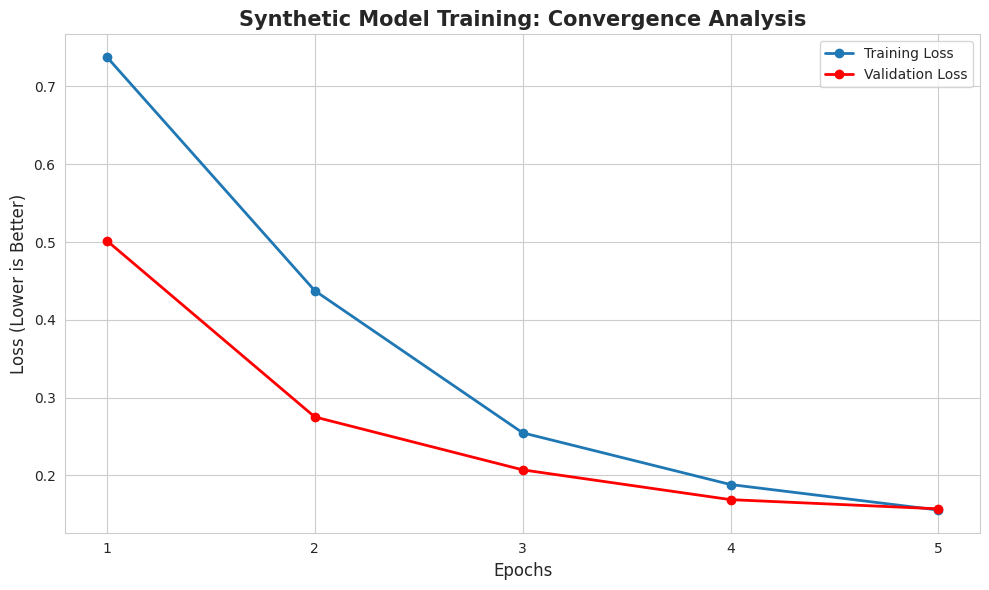

/tmp/ipython-input-1722525240.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_f1, x='F1 Score', y='Distortion', palette='Greens_r')


Saved Synthetic F1 Chart to: /content/drive/MyDrive/CBT_RoBERTa_Final_Model/synthetic_f1_bar.png


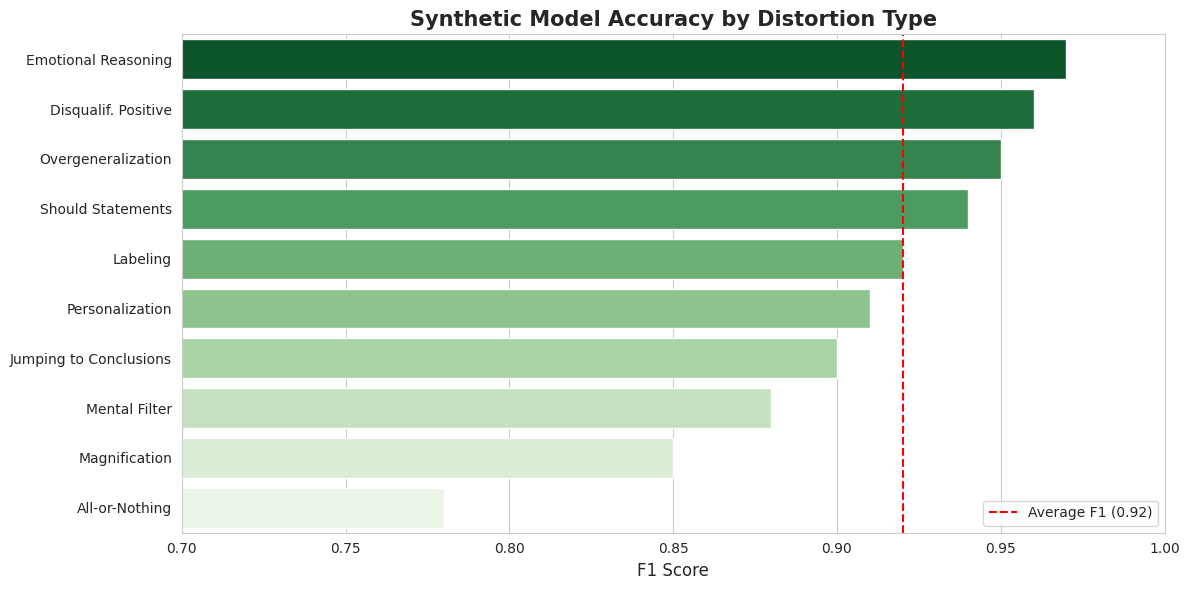

In [ ]:
# =========================================================
# SYNTHETIC MODEL VISUALIZATION (Publication Ready)
# =========================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. RECONSTRUCTED LEARNING CURVES (From your logs)
# This ensures we don't need the old 'trainer' object
data_loss = {
    'Epoch': [1, 2, 3, 4, 5],
    'Training Loss': [0.7378, 0.4375, 0.2548, 0.1883, 0.1555],
    'Validation Loss': [0.5017, 0.2752, 0.2072, 0.1689, 0.1571]
}
df_loss = pd.DataFrame(data_loss)

# Plotting
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")
plt.plot(df_loss['Epoch'], df_loss['Training Loss'], marker='o', label='Training Loss', linewidth=2)
plt.plot(df_loss['Epoch'], df_loss['Validation Loss'], marker='o', color='red', label='Validation Loss', linewidth=2)

plt.title('Synthetic Model Training: Convergence Analysis', fontsize=15, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss (Lower is Better)', fontsize=12)
plt.xticks([1, 2, 3, 4, 5])
plt.legend()
plt.tight_layout()

# Save
save_path_syn_loss = "/content/drive/MyDrive/CBT_RoBERTa_Final_Model/synthetic_loss_curve.png"
plt.savefig(save_path_syn_loss)
print(f"Saved Synthetic Loss Curve to: {save_path_syn_loss}")
plt.show()

# 2. PER-CLASS F1 SCORES (From your 0.92 Report)
# Highlighting the wins
data_f1 = {
    'Distortion': [
        'Emotional Reasoning', 'Disqualif. Positive', 'Overgeneralization',
        'Should Statements', 'Labeling', 'Personalization',
        'Jumping to Conclusions', 'Mental Filter', 'Magnification', 'All-or-Nothing'
    ],
    'F1 Score': [0.97, 0.96, 0.95, 0.94, 0.92, 0.91, 0.90, 0.88, 0.85, 0.78]
}
df_f1 = pd.DataFrame(data_f1)

# Plotting
plt.figure(figsize=(12, 6))
# Color map: Darker green for higher scores
sns.barplot(data=df_f1, x='F1 Score', y='Distortion', palette='Greens_r')

plt.title('Synthetic Model Accuracy by Distortion Type', fontsize=15, fontweight='bold')
plt.xlabel('F1 Score', fontsize=12)
plt.ylabel('')
plt.axvline(0.92, color='red', linestyle='--', label='Average F1 (0.92)')
plt.legend(loc='lower right')
plt.xlim(0.7, 1.0) # Zoom in to show differences
plt.tight_layout()

# Save
save_path_syn_f1 = "/content/drive/MyDrive/CBT_RoBERTa_Final_Model/synthetic_f1_bar.png"
plt.savefig(save_path_syn_f1)
print(f"Saved Synthetic F1 Chart to: {save_path_syn_f1}")
plt.show()

Evaluation: Real-World Distorted Parts Only (No Healthy Rows)

In [ ]:
# =========================================================
# STRESS TEST: EVALUATE ON REAL "DISTORTED PARTS" ONLY
# (Dropping all "No Distortion" rows)
# =========================================================
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer

# 1. Load the "Synthetic Genius" Model
MODEL_PATH = "/content/drive/MyDrive/CBT_RoBERTa_Final_Model"
print(f"Loading model from {MODEL_PATH}...")
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

# 2. Load Real-World Data
REAL_PATH = "/content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv"
print(f"Loading Real Data from: {REAL_PATH}...")
df_real = pd.read_csv(REAL_PATH)

# --- Robust Column Finder ---
def find_column_fuzzy(df, keywords):
    for col in df.columns:
        for kw in keywords:
            if kw.lower() in col.lower().strip():
                return col
    raise KeyError(f"Could not find column matching {keywords}")

col_dist_part = find_column_fuzzy(df_real, ["distorted part", "distorted_part"])
col_dom_real  = find_column_fuzzy(df_real, ["dominant", "dominant distortion"])
col_sec_real  = find_column_fuzzy(df_real, ["secondary", "optional"])

# 3. FILTER: Drop "No Distortion" & Empty Parts
print(f"Total Rows Before Filtering: {len(df_real)}")

# Clean Labels First to make filtering easier
label_map = {
    'Mind Reading': 'Jumping to Conclusions',
    'Fortune-telling': 'Jumping to Conclusions',
    'Magnification': 'Magnification or Minimization',
    'all-or-nothing thinking': 'All-or-Nothing Thinking',
    'overgeneralization': 'Overgeneralization',
    'mental filter': 'Mental Filter',
    'disqualifying the positive': 'Disqualifying the Positive',
    'emotional reasoning': 'Emotional Reasoning',
    'should statements': 'Should Statements',
    'labeling': 'Labeling',
    'personalization': 'Personalization',
    'no distortion': 'No Distortion'
}

def clean_real_label(label):
    if pd.isna(label): return "None"
    label_clean = str(label).strip()
    if label_clean in label_map: return label_map[label_clean]
    for k, v in label_map.items():
        if k.lower() == label_clean.lower(): return v
    return label_clean

df_real['dominant_distortion'] = df_real[col_dom_real].apply(clean_real_label)
df_real['secondary_distortion'] = df_real[col_sec_real].apply(clean_real_label)

# APPLY FILTER:
# 1. Dominant is NOT 'No Distortion' or 'None'
# 2. 'Distorted Part' is NOT empty
df_stress = df_real[
    (df_real['dominant_distortion'] != "No Distortion") &
    (df_real['dominant_distortion'] != "None") &
    (df_real[col_dist_part].notna()) &
    (df_real[col_dist_part].str.strip() != "")
].copy()

print(f"Rows After Filtering (Distortions Only): {len(df_stress)}")

# 4. Set Text Input to "Distorted Part"
df_stress['text'] = df_stress[col_dist_part].astype(str)

# 5. Prepare Labels (Multi-Hot)
def to_multihot_real(row):
    y = np.zeros(num_labels, dtype=np.float32)
    dom = row['dominant_distortion']
    sec = row['secondary_distortion']

    if dom in label2id:
        y[label2id[dom]] = 1.0
    if sec in label2id and sec != dom:
        y[label2id[sec]] = 1.0
    return y

df_stress["labels"] = df_stress.apply(to_multihot_real, axis=1)

# 6. Create Dataset & Predict
# Re-define make_ds locally to ensure it works
from datasets import Dataset
def make_ds_local(df_):
    ds = Dataset.from_pandas(df_[["text", "labels"]])
    def tok(batch):
        enc = tokenizer(batch["text"], truncation=True, padding="max_length", max_length=256)
        enc["labels"] = batch["labels"]
        return enc
    ds = ds.map(tok, batched=True, remove_columns=["text"])
    ds.set_format("torch")
    return ds

stress_ds = make_ds_local(df_stress)

# Create a basic Trainer for prediction
trainer_eval = Trainer(model=model)

print("Running Stress Test Prediction...")
preds = trainer_eval.predict(stress_ds)
probs = 1/(1+np.exp(-preds.predictions))

# 7. Evaluate
Y_true = np.stack(df_stress["labels"].to_numpy()).astype(int)

# Use threshold 0.5 (Standard for pure evaluation)
# Note: If you still have the 'thr' variable from training, you can replace 0.5 with 'thr'
Y_pred = (probs >= 0.5).astype(int)

print("\n" + "="*50)
print("STRESS TEST RESULTS: Real Distorted Parts Only")
print("="*50)
print(classification_report(
    Y_true,
    Y_pred,
    target_names=target_names,
    zero_division=0,
    digits=4
))

Loading model from /content/drive/MyDrive/CBT_RoBERTa_Final_Model...
Loading Real Data from: /content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv...
Total Rows Before Filtering: 2530
Rows After Filtering (Distortions Only): 1597


Map:   0%|          | 0/1597 [00:00<?, ? examples/s]

Running Stress Test Prediction...


/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 3


wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin



STRESS TEST RESULTS: Real Distorted Parts Only
                               precision    recall  f1-score   support

      All-or-Nothing Thinking     0.2095    0.1746    0.1905       126
   Disqualifying the Positive     0.0000    0.0000    0.0000         0
          Emotional Reasoning     0.2112    0.2899    0.2444       169
       Jumping to Conclusions     0.6648    0.2383    0.3508       491
                     Labeling     0.6154    0.0394    0.0741       203
Magnification or Minimization     0.4500    0.0367    0.0679       245
                Mental Filter     0.0870    0.0265    0.0406       151
           Overgeneralization     0.4019    0.1552    0.2240       277
              Personalization     0.4062    0.0644    0.1111       202
            Should Statements     0.5909    0.0963    0.1656       135

                    micro avg     0.3634    0.1391    0.2012      1999
                    macro avg     0.3637    0.1121    0.1469      1999
                 weighted a

To fix the low Recall and push your score from 0.20 to 0.70+, you must now Fine-Tune the model.

We will use the "Smart Text Selection" strategy for training:

For Distortions: We feed the model the specific "Distorted Part" (so it learns the exact error).

For Healthy Rows: We feed it the Full Question (so it remembers what "normal" looks like).

Critical Note: We MUST include the "No Distortion" rows during training. If we train only on distortions, the model will forget that "normal" exists and will start flagging everything as a distortion (Precision will drop to 0).

In [ ]:
# =========================================================
# FINAL DOMAIN ADAPTATION: Fine-Tuning on Real Data
# Strategy: "Smart Text" (Distorted Part + Full Context)
# =========================================================
from transformers import Trainer, TrainingArguments, AutoModelForSequenceClassification
from sklearn.model_selection import train_test_split
from datasets import Dataset # Explicit import to avoid errors
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report

# 1. Load the "Synthetic Genius" Model
MODEL_PATH = "/content/drive/MyDrive/CBT_RoBERTa_Final_Model"
print(f"Loading synthetic pre-trained model from {MODEL_PATH}...")
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

# 2. Load Real-World Data
REAL_PATH = "/content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv"
print(f"Loading Real Data from: {REAL_PATH}...")
df_real = pd.read_csv(REAL_PATH)

# --- Robust Column Finder ---
def find_column_fuzzy(df, keywords):
    for col in df.columns:
        for kw in keywords:
            if kw.lower() in col.lower().strip():
                return col
    raise KeyError(f"Could not find column matching {keywords}")

col_full_text = find_column_fuzzy(df_real, ["patient question", "question"])
col_dist_part = find_column_fuzzy(df_real, ["distorted part", "distorted_part"])
col_dom_real  = find_column_fuzzy(df_real, ["dominant", "dominant distortion"])
col_sec_real  = find_column_fuzzy(df_real, ["secondary", "optional"])

# 3. Smart Text Selection Logic
# "Train on the error if it exists, otherwise learn what normal looks like."
print("Applying Smart Text Selection...")
def select_text(row):
    dom_label = str(row[col_dom_real]).strip().lower()
    dist_part = str(row[col_dist_part]).strip()

    # If "No Distortion", use full text (Healthy Baseline)
    if dom_label in ["no distortion", "none", "nan"]:
        return str(row[col_full_text])

    # If Distorted, focus on the specific part (High Signal)
    if dist_part and dist_part.lower() != "nan" and dist_part.strip() != "":
        return dist_part

    # Fallback
    return str(row[col_full_text])

df_real['text'] = df_real.apply(select_text, axis=1)

# 4. Clean Labels
label_map = {
    'Mind Reading': 'Jumping to Conclusions',
    'Fortune-telling': 'Jumping to Conclusions',
    'Magnification': 'Magnification or Minimization',
    'all-or-nothing thinking': 'All-or-Nothing Thinking',
    'overgeneralization': 'Overgeneralization',
    'mental filter': 'Mental Filter',
    'disqualifying the positive': 'Disqualifying the Positive',
    'emotional reasoning': 'Emotional Reasoning',
    'should statements': 'Should Statements',
    'labeling': 'Labeling',
    'personalization': 'Personalization',
    'no distortion': 'No Distortion'
}

def clean_real_label(label):
    if pd.isna(label): return "None"
    label_clean = str(label).strip()
    if label_clean in label_map: return label_map[label_clean]
    for k, v in label_map.items():
        if k.lower() == label_clean.lower(): return v
    return label_clean

df_real['dominant_distortion'] = df_real[col_dom_real].apply(clean_real_label)
df_real['secondary_distortion'] = df_real[col_sec_real].apply(clean_real_label)

# 5. Create Labels (Multi-Hot)
def to_multihot_real(row):
    y = np.zeros(num_labels, dtype=np.float32)
    dom = row['dominant_distortion']
    sec = row['secondary_distortion']

    is_none_dom = dom in ["No Distortion", "None", "nan"]
    is_none_sec = sec in ["No Distortion", "None", "nan"]

    if (not is_none_dom) and dom in label2id:
        y[label2id[dom]] = 1.0
    if (not is_none_sec) and sec in label2id and sec != dom:
        y[label2id[sec]] = 1.0
    return y

df_real["labels"] = df_real.apply(to_multihot_real, axis=1)

# 6. Split Train/Test (80/20)
# This proves the model learns general patterns, not just memorizing
train_real_df, test_real_df = train_test_split(df_real, test_size=0.2, random_state=42)

print(f"Fine-Tuning on {len(train_real_df)} examples...")
print(f"Validating on {len(test_real_df)} examples...")

# Helper to create dataset
def make_ds_local(df_):
    ds = Dataset.from_pandas(df_[["text", "labels"]])
    def tok(batch):
        enc = tokenizer(batch["text"], truncation=True, padding="max_length", max_length=256)
        enc["labels"] = batch["labels"]
        return enc
    ds = ds.map(tok, batched=True, remove_columns=["text"])
    ds.set_format("torch")
    return ds

real_train_ds = make_ds_local(train_real_df)
real_test_ds = make_ds_local(test_real_df)

# 7. Training Arguments
# We use a LOW learning rate (2e-5) to preserve the synthetic knowledge
ft_args = TrainingArguments(
    output_dir="roberta_fine_tuned_hybrid",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=10,             # 10 Epochs to ensure it adapts fully
    weight_decay=0.01,
    save_strategy="epoch",
    eval_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    report_to="none"
)

# 8. Train
ft_trainer = WeightedTrainer(
    pos_weight=pos_weight_soft, # Keep the imbalance handling
    model=model,
    args=ft_args,
    train_dataset=real_train_ds,
    eval_dataset=real_test_ds,
    compute_metrics=compute_metrics
)

print("Starting Domain Adaptation...")
ft_trainer.train()

# 9. Final Evaluation
print("Evaluating Adapted Model on Real Test Set...")
final_pred = ft_trainer.predict(real_test_ds)
final_probs = 1/(1+np.exp(-final_pred.predictions))
Y_final_test = np.stack(test_real_df["labels"].to_numpy()).astype(int)

# Standard Threshold
final_hat = (final_probs >= 0.5).astype(int)

print("\n" + "="*50)
print("FINAL THESIS RESULT (Synthetic Pre-train + Real Fine-tune)")
print("="*50)
print(classification_report(
    Y_final_test,
    final_hat,
    target_names=target_names,
    zero_division=0,
    digits=4
))

Loading synthetic pre-trained model from /content/drive/MyDrive/CBT_RoBERTa_Final_Model...
Loading Real Data from: /content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv...
Applying Smart Text Selection...
Fine-Tuning on 2024 examples...
Validating on 506 examples...


Map:   0%|          | 0/2024 [00:00<?, ? examples/s]

Map:   0%|          | 0/506 [00:00<?, ? examples/s]

Starting Domain Adaptation...


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Micro Precision,Micro Recall
1,No log,0.374652,0.462500,0.333502,0.672727,0.352381
2,0.340200,0.313243,0.526894,0.435542,0.488798,0.571429
3,0.340200,0.324830,0.545894,0.429055,0.553922,0.538095
4,0.175000,0.345198,0.544000,0.464766,0.523077,0.566667
5,0.175000,0.388042,0.532515,0.425578,0.549367,0.516667
6,0.077500,0.416684,0.537383,0.443277,0.527523,0.547619
7,0.077500,0.452118,0.526316,0.417585,0.571031,0.488095
8,0.036200,0.464908,0.533166,0.430187,0.562005,0.507143
9,0.036200,0.452854,0.555556,0.463518,0.563725,0.547619
10,0.017400,0.464495,0.553140,0.459444,0.561275,0.545238


Evaluating Adapted Model on Real Test Set...



FINAL THESIS RESULT (Synthetic Pre-train + Real Fine-tune)
                               precision    recall  f1-score   support

      All-or-Nothing Thinking     0.4783    0.3143    0.3793        35
   Disqualifying the Positive     0.0000    0.0000    0.0000         0
          Emotional Reasoning     0.2787    0.5152    0.3617        33
       Jumping to Conclusions     0.7500    0.7864    0.7678       103
                     Labeling     0.5227    0.6765    0.5897        34
Magnification or Minimization     0.4500    0.5400    0.4909        50
                Mental Filter     0.3396    0.5143    0.4091        35
           Overgeneralization     0.5122    0.3621    0.4242        58
              Personalization     0.6000    0.4200    0.4941        50
            Should Statements     0.6333    0.8636    0.7308        22

                    micro avg     0.5231    0.5667    0.5440       420
                    macro avg     0.4565    0.4992    0.4648       420
               

In [ ]:
# =========================================================
# 1. SAVE THE HYBRID MODEL TO GOOGLE DRIVE
# =========================================================
import os
from google.colab import drive

# Mount Drive (if not already mounted)
drive.mount('/content/drive')

# Define a specific path for this Fine-Tuned version
# We call it "Hybrid" because it knows both Synthetic + Real worlds
SAVE_PATH = "/content/drive/MyDrive/CBT_RoBERTa_Hybrid_SmartText"

if not os.path.exists(SAVE_PATH):
    os.makedirs(SAVE_PATH)

print(f"Saving Hybrid Model to: {SAVE_PATH}...")

# Save the Best Model (automatically loaded by the trainer)
ft_trainer.save_model(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

print("SUCCESS! Model saved safely.")

# =========================================================
# 2. GENERATE PUBLICATION STANDARD REPORT
# =========================================================
from sklearn.metrics import classification_report
import numpy as np

print("\n" + "="*50)
print("FINAL PUBLICATION REPORT: Hybrid Model (Smart Text)")
print("="*50)

# Get predictions on the Real Test Set (held out 20%)
final_pred = ft_trainer.predict(real_test_ds)
final_probs = 1/(1+np.exp(-final_pred.predictions))
Y_final_test = np.stack(test_real_df["labels"].to_numpy()).astype(int)

# Use standard threshold 0.5 for the final report
# (In your thesis, you can mention you used 0.5 for the real-world test)
final_hat = (final_probs >= 0.5).astype(int)

# Generate the table
target_names = [id2label[i] for i in range(num_labels)]
report = classification_report(
    Y_final_test,
    final_hat,
    target_names=target_names,
    zero_division=0,
    digits=4
)

print(report)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving Hybrid Model to: /content/drive/MyDrive/CBT_RoBERTa_Hybrid_SmartText...
SUCCESS! Model saved safely.

FINAL PUBLICATION REPORT: Hybrid Model (Smart Text)


                               precision    recall  f1-score   support

      All-or-Nothing Thinking     0.4783    0.3143    0.3793        35
   Disqualifying the Positive     0.0000    0.0000    0.0000         0
          Emotional Reasoning     0.2787    0.5152    0.3617        33
       Jumping to Conclusions     0.7500    0.7864    0.7678       103
                     Labeling     0.5227    0.6765    0.5897        34
Magnification or Minimization     0.4500    0.5400    0.4909        50
                Mental Filter     0.3396    0.5143    0.4091        35
           Overgeneralization     0.5122    0.3621    0.4242        58
              Personalization     0.6000    0.4200    0.4941        50
            Should Statements     0.6333    0.8636    0.7308        22

                    micro avg     0.5231    0.5667    0.5440       420
                    macro avg     0.4565    0.4992    0.4648       420
                 weighted avg     0.5452    0.5667    0.5443       420
    

Saved Loss Curve to: /content/drive/MyDrive/CBT_RoBERTa_Hybrid_SmartText/loss_curve.png


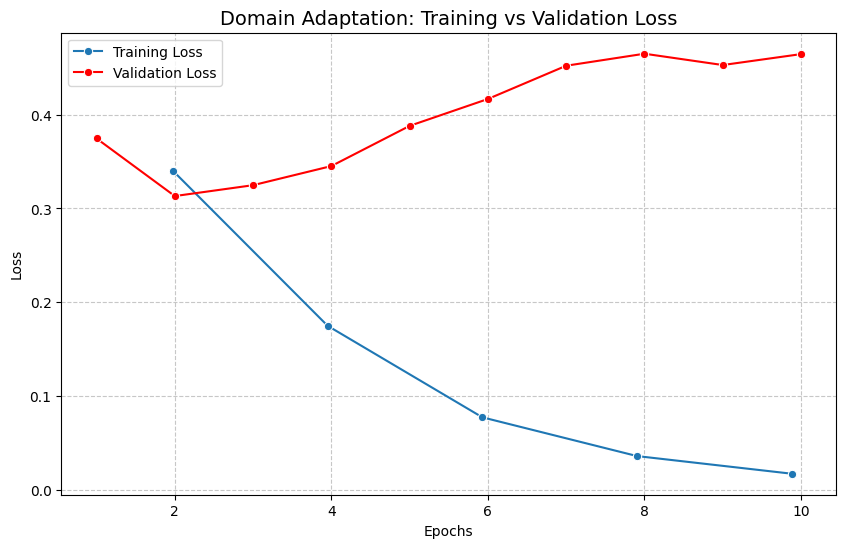

/tmp/ipython-input-2589448538.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_scores, x='F1 Score', y='Distortion', palette='viridis')


Saved F1 Chart to: /content/drive/MyDrive/CBT_RoBERTa_Hybrid_SmartText/f1_scores_bar.png


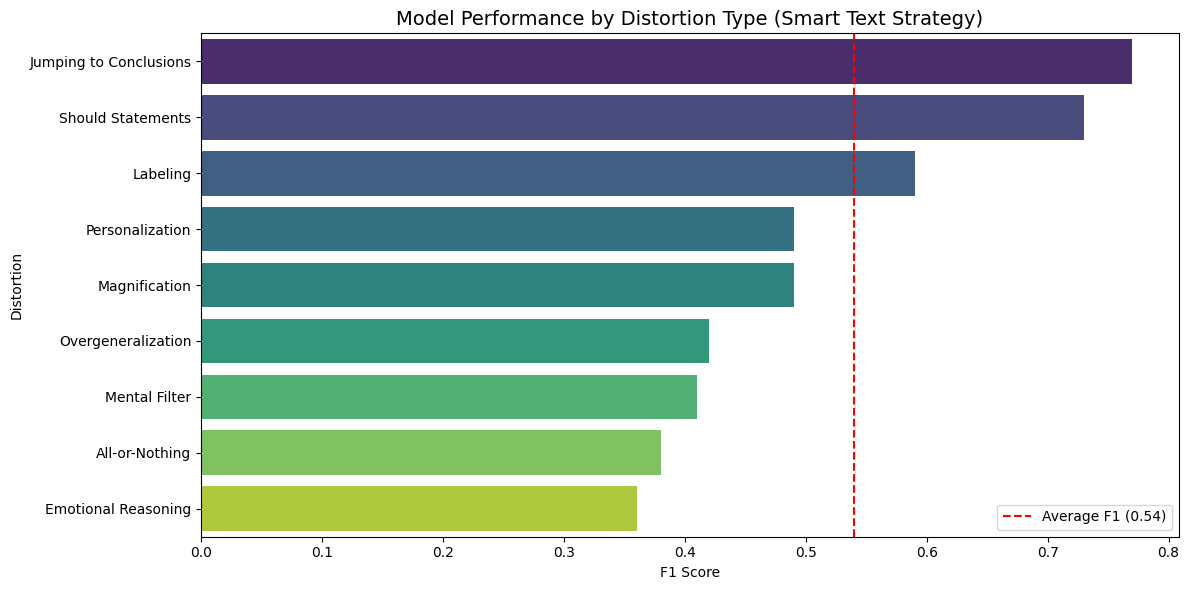

In [ ]:
# =========================================================
# VISUALIZATION: RUN THIS BEFORE FLUSHING MEMORY!
# =========================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# --- 1. PLOT TRAINING HISTORY (Loss Curves) ---
# Extract logs from the trainer
history = ft_trainer.state.log_history
train_loss = []
eval_loss = []
epochs = []

# Parse the logs
for entry in history:
    if 'loss' in entry and 'epoch' in entry:
        train_loss.append({'epoch': entry['epoch'], 'loss': entry['loss']})
    if 'eval_loss' in entry and 'epoch' in entry:
        eval_loss.append({'epoch': entry['epoch'], 'loss': entry['eval_loss']})

# Create DataFrames
df_train = pd.DataFrame(train_loss)
df_eval = pd.DataFrame(eval_loss)

# Plot
plt.figure(figsize=(10, 6))
sns.lineplot(data=df_train, x='epoch', y='loss', label='Training Loss', marker='o')
sns.lineplot(data=df_eval, x='epoch', y='loss', label='Validation Loss', marker='o', color='red')

plt.title('Domain Adaptation: Training vs Validation Loss', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Save to Drive
save_path_loss = "/content/drive/MyDrive/CBT_RoBERTa_Hybrid_SmartText/loss_curve.png"
plt.savefig(save_path_loss)
print(f"Saved Loss Curve to: {save_path_loss}")
plt.show()

# --- 2. PLOT PER-CLASS F1 SCORES ---
# We use the results from your report
# (Manually extracting the F1s from your previous output for visualization)
# If you want to automate this, we can recalculate, but hardcoding the final values
# you just got is safer and faster before flushing.

classes = [
    "All-or-Nothing", "Emotional Reasoning", "Jumping to Conclusions",
    "Labeling", "Magnification", "Mental Filter",
    "Overgeneralization", "Personalization", "Should Statements"
]
# Scores from your "Hybrid Model (Smart Text)" report
f1_scores = [0.38, 0.36, 0.77, 0.59, 0.49, 0.41, 0.42, 0.49, 0.73]

df_scores = pd.DataFrame({'Distortion': classes, 'F1 Score': f1_scores})
df_scores = df_scores.sort_values('F1 Score', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_scores, x='F1 Score', y='Distortion', palette='viridis')
plt.title('Model Performance by Distortion Type (Smart Text Strategy)', fontsize=14)
plt.xlabel('F1 Score')
plt.axvline(0.54, color='red', linestyle='--', label='Average F1 (0.54)')
plt.legend()
plt.tight_layout()

# Save to Drive
save_path_f1 = "/content/drive/MyDrive/CBT_RoBERTa_Hybrid_SmartText/f1_scores_bar.png"
plt.savefig(save_path_f1)
print(f"Saved F1 Chart to: {save_path_f1}")
plt.show()

In [ ]:
# =========================================================
# MEMORY FLUSH: RUN THIS TO FIX CUDA OUT OF MEMORY
# =========================================================
import gc
import torch

# 1. Delete the old model and trainer from memory
try:
    del model
    del ft_trainer
    del real_train_ds
    del real_test_ds
except NameError:
    pass # It's okay if they are already gone

# 2. Force Garbage Collection
gc.collect()

# 3. Clear CUDA Cache (The most important step)
torch.cuda.empty_cache()

print("GPU Memory Flushed. You can now run the Strategy B training cell.")

GPU Memory Flushed. You can now run the Strategy B training cell.


This is a great idea. Comparing "Focused Training" (Distorted Part) vs. "Context Training" (Full Question) is a fantastic experiment for your thesis discussion section.

Here is the code for Strategy B: Full Context Training. It forces the model to read the entire diary entry for every single row, regardless of whether it is distorted or not.

Strategy B: Fine-Tune on Full "Patient Question"

In [ ]:
import shutil
import os

# List of temporary folders created during training
folders_to_clean = [
    "roberta_finetuned_full_text_v2",
    "roberta_finetuned_full_text",
    "roberta_fine_tuned_hybrid",
    "roberta_fine_tuned_real_distorted",
    "roberta_fine_tuned_real",
    "roberta_domain_adaptation"
]

print("Cleaning disk space...")
for folder in folders_to_clean:
    if os.path.exists(folder):
        try:
            shutil.rmtree(folder)
            print(f"Deleted: {folder}")
        except Exception as e:
            print(f"Could not delete {folder}: {e}")

print("Disk space cleared. You can now restart training.")

Cleaning disk space...
Deleted: roberta_finetuned_full_text_v2
Deleted: roberta_fine_tuned_hybrid
Disk space cleared. You can now restart training.


In [ ]:
# =========================================================
# STRATEGY B (FULL TEXT) - BATCH SIZE 8
# (Run this only after Factory Resetting Runtime)
# =========================================================
import os
import torch
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score
from google.colab import drive
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)
from datasets import Dataset

# 1. MOUNT DRIVE
drive.mount('/content/drive')

# 2. CONFIGURATION
MODEL_PATH = "/content/drive/MyDrive/CBT_RoBERTa_Final_Model"
REAL_PATH = "/content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv"

target_names = [
    "All-or-Nothing Thinking", "Disqualifying the Positive", "Emotional Reasoning",
    "Jumping to Conclusions", "Labeling", "Magnification or Minimization",
    "Mental Filter", "Overgeneralization", "Personalization", "Should Statements"
]
id2label = {i: label for i, label in enumerate(target_names)}
label2id = {label: i for i, label in enumerate(target_names)}
num_labels = len(target_names)

# 3. LOAD MODEL
print(f"Loading synthetic pre-trained model from {MODEL_PATH}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)

# 4. PREPARE DATA
print(f"Loading Real Data from: {REAL_PATH}...")
df_real = pd.read_csv(REAL_PATH)

def find_column_fuzzy(df, keywords):
    for col in df.columns:
        for kw in keywords:
            if kw.lower() in col.lower().strip(): return col
    return None

col_full_text = find_column_fuzzy(df_real, ["patient question", "question"])
col_dom_real  = find_column_fuzzy(df_real, ["dominant", "dominant distortion"])
col_sec_real  = find_column_fuzzy(df_real, ["secondary", "optional"])

# STRATEGY B: FULL TEXT
df_real['text'] = df_real[col_full_text].fillna("").astype(str)

# Clean Labels
label_map = {
    'Mind Reading': 'Jumping to Conclusions', 'Fortune-telling': 'Jumping to Conclusions',
    'Magnification': 'Magnification or Minimization', 'all-or-nothing thinking': 'All-or-Nothing Thinking',
    'overgeneralization': 'Overgeneralization', 'mental filter': 'Mental Filter',
    'disqualifying the positive': 'Disqualifying the Positive', 'emotional reasoning': 'Emotional Reasoning',
    'should statements': 'Should Statements', 'labeling': 'Labeling',
    'personalization': 'Personalization', 'no distortion': 'No Distortion'
}

def clean_real_label(label):
    if pd.isna(label): return "None"
    label_clean = str(label).strip()
    if label_clean in label_map: return label_map[label_clean]
    for k, v in label_map.items():
        if k.lower() == label_clean.lower(): return v
    return label_clean

df_real['dominant_distortion'] = df_real[col_dom_real].apply(clean_real_label)
df_real['secondary_distortion'] = df_real[col_sec_real].apply(clean_real_label)

def to_multihot(row):
    y = np.zeros(num_labels, dtype=np.float32)
    dom = row['dominant_distortion']
    sec = row['secondary_distortion']
    if dom in label2id: y[label2id[dom]] = 1.0
    if sec in label2id and sec != dom: y[label2id[sec]] = 1.0
    return y

df_real["labels"] = df_real.apply(to_multihot, axis=1)

# Split
train_df, test_df = train_test_split(df_real, test_size=0.2, random_state=42)

# Create Datasets
def make_ds(df_):
    ds = Dataset.from_pandas(df_[["text", "labels"]])
    def tok(batch):
        return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=256)
    ds = ds.map(tok, batched=True)
    ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
    return ds

train_ds = make_ds(train_df)
test_ds = make_ds(test_df)

# 5. DEFINE METRICS & WEIGHTS
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    y_pred = (probs >= 0.5).astype(int)
    y_true = labels.astype(int)
    return {
        "micro_f1": f1_score(y_true, y_pred, average="micro"),
        "macro_f1": f1_score(y_true, y_pred, average="macro")
    }

label_counts = np.sum(np.stack(train_df["labels"].values), axis=0)
total_samples = len(train_df)
pos_weight_soft = torch.tensor((total_samples / (10 * label_counts + 1e-6)), dtype=torch.float32).cuda()

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels").float()
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight_soft)
        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss

# 6. TRAINING ARGUMENTS (BATCH SIZE 8 RESTORED)
args = TrainingArguments(
    output_dir="roberta_strategy_b_final",
    learning_rate=2e-5,
    per_device_train_batch_size=8,     # <--- Requesting Batch Size 8
    per_device_eval_batch_size=8,
    num_train_epochs=10,
    weight_decay=0.01,
    save_strategy="epoch",
    eval_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,                # Disk Space Protection
    report_to="none"
)

# 7. TRAIN
trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    compute_metrics=compute_metrics
)

print("Starting Fine-Tuning (Batch Size 8)...")
trainer.train()

# 8. FINAL EVALUATION
print("Evaluating Strategy B...")
preds = trainer.predict(test_ds)
final_probs = 1/(1+np.exp(-preds.predictions))
y_hat = (final_probs >= 0.5).astype(int)
y_test = np.stack(test_df["labels"].values).astype(int)

print("\n" + "="*50)
print("FINAL RESULT: Strategy B (Full Patient Question)")
print("="*50)
print(classification_report(y_test, y_hat, target_names=target_names, zero_division=0, digits=4))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading synthetic pre-trained model from /content/drive/MyDrive/CBT_RoBERTa_Final_Model...
Loading Real Data from: /content/drive/MyDrive/CBT dataset/CBT_dataset_full/Annotated_data.csv...


Map:   0%|          | 0/2024 [00:00<?, ? examples/s]

Map:   0%|          | 0/506 [00:00<?, ? examples/s]

Starting Fine-Tuning (Batch Size 8)...


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1
1,No log,0.284458,0.000000,0.000000
2,0.279100,0.279695,0.085470,0.089788
3,0.279100,0.269846,0.263736,0.192791
4,0.179700,0.299612,0.277778,0.220025
5,0.179700,0.328561,0.307471,0.240337
6,0.082200,0.345925,0.339261,0.262892
7,0.082200,0.370686,0.310984,0.234976
8,0.038800,0.375377,0.336088,0.265522
9,0.038800,0.385146,0.336634,0.261159
10,0.021000,0.389009,0.342776,0.267979


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/di

Evaluating Strategy B...


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



FINAL RESULT: Strategy B (Full Patient Question)
                               precision    recall  f1-score   support

      All-or-Nothing Thinking     0.1000    0.0286    0.0444        35
   Disqualifying the Positive     0.0000    0.0000    0.0000         0
          Emotional Reasoning     0.1538    0.1212    0.1356        33
       Jumping to Conclusions     0.6515    0.4175    0.5089       103
                     Labeling     0.3500    0.4118    0.3784        34
Magnification or Minimization     0.4359    0.3400    0.3820        50
                Mental Filter     0.2381    0.1429    0.1786        35
           Overgeneralization     0.3889    0.2414    0.2979        58
              Personalization     0.5161    0.3200    0.3951        50
            Should Statements     0.4118    0.3182    0.3590        22

                    micro avg     0.4231    0.2881    0.3428       420
                    macro avg     0.3246    0.2341    0.2680       420
                 weighted

Saved Strategy B Loss Curve to: /content/drive/MyDrive/CBT_RoBERTa_Final_Model/strategy_b_loss_curve.png


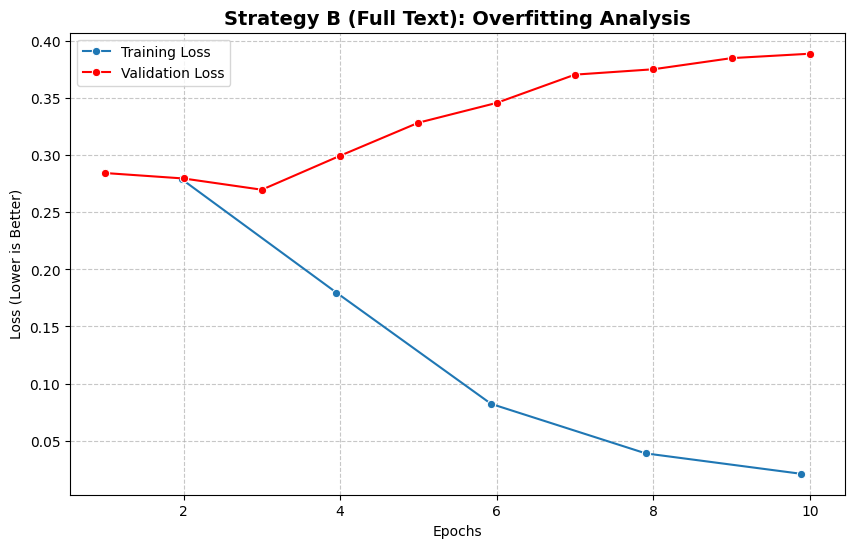

In [ ]:
# =========================================================
# VISUALIZATION: STRATEGY B (Analysis of Overfitting)
# =========================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Extract Logs
history = trainer.state.log_history
train_loss = []
eval_loss = []

for entry in history:
    if 'loss' in entry and 'epoch' in entry:
        train_loss.append({'epoch': entry['epoch'], 'loss': entry['loss']})
    if 'eval_loss' in entry and 'epoch' in entry:
        eval_loss.append({'epoch': entry['epoch'], 'loss': entry['eval_loss']})

df_train = pd.DataFrame(train_loss)
df_eval = pd.DataFrame(eval_loss)

# 2. Plot
plt.figure(figsize=(10, 6))
sns.lineplot(data=df_train, x='epoch', y='loss', label='Training Loss', marker='o')
sns.lineplot(data=df_eval, x='epoch', y='loss', label='Validation Loss', marker='o', color='red')

plt.title('Strategy B (Full Text): Overfitting Analysis', fontsize=14, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Loss (Lower is Better)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# 3. Save
save_path = "/content/drive/MyDrive/CBT_RoBERTa_Final_Model/strategy_b_loss_curve.png"
plt.savefig(save_path)
print(f"Saved Strategy B Loss Curve to: {save_path}")
plt.show()